# Theo pipeline parameter search — results analysis

Scans every finished run under `theo_pipeline_params_search/`, builds a tidy
table of R² (and wall-clock runtime) per (run, model, PC), reports what's
actually been tested so far, and plots parameter effects per model.

**Re-run this notebook any time** to pick up newly-finished runs — it only
reads small `run_params.json` / `cv_summary.json` / log files, not the big
per-run pickles/models, so it stays fast no matter how large the search
directory gets. Needs `pandas` + `matplotlib` (any recent env with those two
works, e.g. this repo's `decoding` conda env, or base anaconda).

## Held-out test set

Every run reserves the **last 20% of samples in time as a holdout**
(`--holdout-frac 0.2`, excluded from the CV folds entirely). But
**`evaluate_holdout` is `False` on every run in this search** (checked below
across all completed runs) — no R² has ever been computed on that held-out
data. It was set aside but never scored. Every R² in this notebook is a
cross-validated (in-search) estimate only.

## What `oof_r2` actually is

Traced through `theo_pipeline_new.py`: for each model, `kf.split(...)`
produces `n_splits` folds over the **search portion only** (holdout excluded
before this even starts). Each fold's test predictions get written into
`oof_pred[test_idx]` — so after all folds, `oof_pred` holds exactly one
out-of-fold prediction for every sample in the search portion, pooled
together. Then:

```python
overall = r2_score(y_search, oof_pred, multioutput="raw_values")   # oof_r2_per_output
```

**One R² computed once over the entire concatenated search-portion trace**
(not an average of per-fold R²s — that's the separate, noisier
`mean_fold_r2` also in the table). Every sample contributes to the number
exactly once, from whichever fold held it out. This is standard "OOF R²" and
is why it's used as the primary test-set metric here: `mean_fold_r2` is the
mean of 5-10 R²s each computed on a small held-out chunk, and a couple of
unlucky small/hard chunks can swing that mean deeply negative even when the
model is fine overall (concrete example in the coverage section below).

Still **not** the same as holdout R² — `oof_pred` never touches the reserved
20% at the end of the recording.

## Setup

In [1]:
import json
import re
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

GLC6962_SEARCH_ROOT = Path("/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/theo_pipeline_params_search")
GLC7189_SEARCH_ROOT = Path("/nexus/posix0/MBR-neuralsystems/ephys/GLC7189/GLC7189_c_g0/theo_pipeline_params_search")
SEARCH_ROOT = GLC7189_SEARCH_ROOT  # point at whichever animal/session you're currently inspecting
RESULTS_ROOT = SEARCH_ROOT / "results"  # individual run dirs live here, not directly under SEARCH_ROOT
PLOTS_DIR = SEARCH_ROOT / "analysis_plots"
PLOTS_DIR.mkdir(exist_ok=True)

MODEL_HP_COLS = {
    "WF": [],
    "WC": ["wc_degree"],
    "SVR": ["svr_c", "svr_max_iter"],
    "XGB": ["xgb_max_depth", "xgb_n_estimators", "xgb_learning_rate"],
    "FNN": ["fnn_num_units", "fnn_frac_dropout", "fnn_max_epochs", "fnn_n_layers"],
    "RNN": ["rnn_num_units", "rnn_frac_dropout", "rnn_max_epochs"],  # no rnn_n_layers -- RNN's module has no such param
    "GRU": ["gru_num_units", "gru_frac_dropout", "gru_max_epochs", "gru_n_layers"],
    "LSTM": ["lstm_num_units", "lstm_frac_dropout", "lstm_max_epochs", "lstm_n_layers"],
}
# Anchor point for "hold everything else fixed" marginal plots. SVR uses
# max_iter=2000 here, NOT theo_pipeline_new.py's own argparse default of
# 5000 -- max_iter=5000 timed out (8h wall-clock limit) on 17/24 completed
# SVR runs that hit it (all 6 base-grid C values, plus 11/24 of the dt/bin
# sweep rows), so there's barely any usable data at that anchor. 2000 is
# fully covered and fast -- see the runtime row in the plots below.
MODEL_DEFAULTS = {
    "WC": {"wc_degree": 3},
    "SVR": {"svr_c": 3.0, "svr_max_iter": 2000},
    "XGB": {"xgb_max_depth": 3, "xgb_n_estimators": 200, "xgb_learning_rate": 0.1},
    "FNN": {"fnn_num_units": 400, "fnn_frac_dropout": 0.25, "fnn_max_epochs": 10, "fnn_n_layers": 2},
    "RNN": {"rnn_num_units": 400, "rnn_frac_dropout": 0.25, "rnn_max_epochs": 10},
    "GRU": {"gru_num_units": 400, "gru_frac_dropout": 0.25, "gru_max_epochs": 10, "gru_n_layers": 2},
    "LSTM": {"lstm_num_units": 400, "lstm_frac_dropout": 0.25, "lstm_max_epochs": 10, "lstm_n_layers": 2},
}
PREPROC_COLS = ["dt", "bin_before", "bin_current", "bin_after", "n_splits", "spike_thresh",
                "input_preprocess", "output_preprocess", "channel_smooth_window",
                "channel_smooth_overlap", "holdout_frac"]
PREPROC_DEFAULTS = {"dt": 0.2, "bin_before": 6, "bin_current": 1, "bin_after": 6, "n_splits": 10, "spike_thresh": 0}

R2_YLIM = (-0.2, 1.0)      # fixed range for every R2 row -- lines/points clip at the edge, never autoscales to outliers
RUNTIME_YLIM = (0, 120)    # fixed range for every runtime row, in minutes -- same clipping convention
GPU_MODELS = ["FNN", "RNN", "GRU", "LSTM"]
CPU_MODELS = ["WF", "WC", "SVR", "XGB"]

# Every sweep plot below is a grid: one row per entry here, one column per
# panel (model / facet). Same 3 rows everywhere for consistency.
METRIC_ROWS = [
    ("oof_r2", R2_YLIM, "OOF test R2"),
    ("mean_fold_train_r2", R2_YLIM, "train R2"),
    ("runtime_min", RUNTIME_YLIM, "runtime (min)"),
]

print("Search root:", SEARCH_ROOT)

Search root: /nexus/posix0/MBR-neuralsystems/ephys/GLC7189/GLC7189_c_g0/theo_pipeline_params_search


## Load every finished run into one tidy table (one row per run x model x PC), plus per-run wall-clock time

In [2]:
def scan_runtimes(search_root):
    '''Match each run to its log file via the "Saved run params -> ..." line
    the pipeline prints, then pull Start time / End time from that same log.'''
    run_time = {}
    for f in (search_root / "logs").glob("*.log"):
        text = f.read_text(errors="replace")
        m = re.search(r"^Saved run params\s+-> (.+)/run_params\.json", text, re.M)
        if not m:
            continue
        run_dir = Path(m.group(1)).name
        start_m = re.search(r"^Start time: (\S+)", text, re.M)
        end_m = re.search(r"^End time: (\S+)", text, re.M)
        if start_m and end_m:
            start = datetime.fromisoformat(start_m.group(1))
            end = datetime.fromisoformat(end_m.group(1))
            run_time[run_dir] = (end - start).total_seconds()
    return run_time

runtime_by_run = scan_runtimes(SEARCH_ROOT)
print(f"{len(runtime_by_run)} runs matched to a log with start+end time.")

rows = []
incomplete_runs = []
for run_dir in sorted(RESULTS_ROOT.glob("[0-9][0-9][0-9][0-9][0-9][0-9][0-9][0-9]_*")):
    if not run_dir.is_dir():
        continue
    params_f, summary_f = run_dir / "run_params.json", run_dir / "cv_summary.json"
    if not params_f.exists() or not summary_f.exists():
        incomplete_runs.append(run_dir.name)
        continue
    params = json.loads(params_f.read_text())
    summary = json.loads(summary_f.read_text())
    cli = params["cli_args"]
    pc_cols = params["resolved"]["pc_cols"]
    runtime_sec = runtime_by_run.get(run_dir.name)

    for model, m in summary.get("models", {}).items():
        # .get(c, default) not .get(c) everywhere below -- runs from before a
        # given flag existed (e.g. --spike-thresh, --fnn-n-layers) have no such
        # key in cli_args at all, and should read as that flag's old hardcoded
        # behavior, not None/NaN (which would silently drop every pre-existing
        # run out of every plot filtered to the default).
        hp_vals = {c: cli.get(c, MODEL_DEFAULTS.get(model, {}).get(c)) for c in MODEL_HP_COLS.get(model, [])}
        preproc_vals = {c: cli.get(c, PREPROC_DEFAULTS.get(c)) for c in PREPROC_COLS}
        oof = m.get("oof_r2_per_output")
        mean_fold = m.get("mean_fold_r2_per_output")
        mean_fold_train = m.get("mean_fold_train_r2_per_output")
        fold_raw = m.get("fold_r2_raw_values")
        for i, pc in enumerate(pc_cols):
            row = {
                "run_dir": run_dir.name,
                "timestamp": params.get("timestamp"),
                "model": model,
                "pc": pc,
                "oof_r2": oof[i] if oof else np.nan,
                "mean_fold_r2": mean_fold[i] if mean_fold else np.nan,
                "mean_fold_train_r2": mean_fold_train[i] if mean_fold_train else np.nan,
                "fold_r2_std": float(np.std([f[i] for f in fold_raw])) if fold_raw else np.nan,
                "runtime_sec": runtime_sec,
                "runtime_min": runtime_sec / 60 if runtime_sec is not None else np.nan,
                "evaluate_holdout": cli.get("evaluate_holdout", False),
            }
            row.update(hp_vals)
            row.update(preproc_vals)
            rows.append(row)

df = pd.DataFrame(rows)
df.to_csv(PLOTS_DIR / "all_runs_long.csv", index=False)

print(f"{df['run_dir'].nunique()} completed runs loaded ({len(df)} run x model x PC rows).")
print(f"{len(incomplete_runs)} run directories are still in progress or permanently failed (no cv_summary.json) -- skipped.")
print()
print("Completed runs per model:")
print(df["model"].value_counts().to_string())
print()
print(f"{df['runtime_sec'].isna().sum()} rows missing a runtime match (should be 0).")
assert not df["evaluate_holdout"].any(), "evaluate_holdout is no longer always False -- update the markdown note above"
print("Confirmed: evaluate_holdout is False on every completed run.")

1947 runs matched to a log with start+end time.
1948 completed runs loaded (9740 run x model x PC rows).
25 run directories are still in progress or permanently failed (no cv_summary.json) -- skipped.

Completed runs per model:
LSTM    3600
GRU     3600
FNN      960
RNN      900
XGB      395
WC       195
SVR       90

5 rows missing a runtime match (should be 0).
Confirmed: evaluate_holdout is False on every completed run.


## Coverage — what's actually been tested per model

`oof_r2` vs `mean_fold_r2` for the same run (why this notebook standardizes
on `oof_r2`):

In [3]:
example = df[df.model == "SVR"].iloc[:5][["run_dir", "pc", "oof_r2", "mean_fold_r2"]]
print(example.to_string(index=False))
print()
print("-> mean_fold_r2 swings far more negative: a couple of small, hard test folds")
print("   dominate the mean-of-per-fold-R2 metric. oof_r2 (one R2 over the pooled")
print("   out-of-fold predictions) is the steadier estimate -- see markdown above.")

                        run_dir  pc    oof_r2  mean_fold_r2
20260808_023103_SVR_c0.3_mi1000 PC1 -0.132561    -48.985811
20260808_023103_SVR_c0.3_mi1000 PC2 -0.170440    -10.145121
20260808_023103_SVR_c0.3_mi1000 PC3 -0.154708    -11.858799
20260808_023103_SVR_c0.3_mi1000 PC4 -0.432187    -11.006199
20260808_023103_SVR_c0.3_mi1000 PC5 -0.048891     -6.285437

-> mean_fold_r2 swings far more negative: a couple of small, hard test folds
   dominate the mean-of-per-fold-R2 metric. oof_r2 (one R2 over the pooled
   out-of-fold predictions) is the steadier estimate -- see markdown above.


In [4]:
def coverage_report(df):
    recs = []
    for model, hp_cols in MODEL_HP_COLS.items():
        sub = df[df["model"] == model]
        if sub.empty:
            recs.append({"model": model, "n_runs": 0, "hyperparams_tested": "(none finished yet)",
                         "preprocessing_variants_tested": "(none finished yet)"})
            continue
        runs = sub.drop_duplicates("run_dir")
        if hp_cols:
            hp_summary = "; ".join(f"{c}={sorted(runs[c].dropna().unique().tolist())}" for c in hp_cols)
        else:
            hp_summary = "(no model-specific hyperparameter -- WF picks alpha via internal RidgeCV)"
        preproc_varied = [c for c in PREPROC_COLS if runs[c].nunique() > 1]
        preproc_summary = "; ".join(f"{c}={sorted(runs[c].dropna().unique().tolist())}" for c in preproc_varied) \
            if preproc_varied else "(all fixed at default)"
        recs.append({"model": model, "n_runs": len(runs),
                     "hyperparams_tested": hp_summary,
                     "preprocessing_variants_tested": preproc_summary})
    return pd.DataFrame(recs)

pd.set_option("display.max_colwidth", 160)
cov = coverage_report(df)
cov.to_csv(PLOTS_DIR / "coverage_report.csv", index=False)
print(cov.to_string(index=False))

model  n_runs                                                                                                                                                                             hyperparams_tested                                                                         preprocessing_variants_tested
   WF       0                                                                                                                                                                            (none finished yet)                                                                                   (none finished yet)
   WC      39                                                                                                                                                                 wc_degree=[1.0, 2.0, 3.0, 4.0] dt=[0.1, 0.2, 0.5]; bin_before=[1, 3, 5, 6, 10]; bin_after=[1, 3, 5, 6, 10]; n_splits=[5, 10, 15, 20]
  SVR      18                                                                  

## Plot conventions used throughout

Every sweep below is **one PNG, one figure, 3 stacked rows** (same columns
in every row):

1. **OOF test R²** (`oof_r2`)
2. **train R²** (`mean_fold_train_r2`, in-sample, averaged over folds)
3. **wall-clock runtime** (minutes, Start time to End time from the run's log)

Row 1 and row 2 (both R²) share a **fixed y-axis of (-0.2, 1)** — a point or
line outside that band is simply clipped at the edge, never autoscaled to
outliers. Row 3 (runtime) autoscales normally, different units.

- **Point = mean**, **error bar = min-to-max range** (not std) across the 5
  PCs (or across runs, for a parameter value matched by more than one run).
- **One-parameter-at-a-time marginals** hold every other model
  hyperparameter *and* every preprocessing knob fixed at `MODEL_DEFAULTS` /
  `PREPROC_DEFAULTS` above.
- Plots with a second varied parameter (e.g. SVR `C` by `max_iter`) show it
  as multiple colored lines **in every row**, same color per value throughout.
- **Heatmaps** (models with >1 hyperparameter) use the same 3-row layout,
  columns are the heatmap's facet dimension (e.g. XGB's `learning_rate`).
  Grey cells = no completed run yet.

In [5]:
def _filter(sub, fixed):
    for k, v in fixed.items():
        if k not in sub.columns:
            continue
        sub = sub[np.isclose(sub[k].astype(float), v)] if pd.api.types.is_numeric_dtype(sub[k]) else sub[sub[k] == v]
    return sub

def _range_yerr(agg):
    lo = (agg["mean"] - agg["min"]).clip(lower=0)
    hi = (agg["max"] - agg["mean"]).clip(lower=0)
    return np.vstack([lo.values, hi.values])

def _set_x_domain(ax, full_x_domain, logx):
    '''Fix x ticks/limits to the FULL set of values this parameter is ever
    tested at for this model (not just whatever's present after filtering to
    one anchor) -- so a panel with only 1 of e.g. 4 dt values completed still
    shows the right context instead of matplotlib auto-zooming to a single
    point and looking broken.'''
    if not full_x_domain or len(full_x_domain) < 2:
        return
    xs = sorted(full_x_domain)
    ax.set_xticks(xs)
    # Explicit labels always -- matplotlib's default log-scale formatter only
    # labels "nice" decade positions and silently hides ticks at arbitrary
    # values like 300/5000/20000, otherwise.
    ax.set_xticklabels([f"{x:g}" for x in xs])
    if logx:
        lo, hi = xs[0] / 1.3, xs[-1] * 1.3
    else:
        margin = (xs[-1] - xs[0]) * 0.08
        lo, hi = xs[0] - margin, xs[-1] + margin
    ax.set_xlim(lo, hi)

def _dot_overlay(ax, sub, x_col, metric, agg, color):
    '''Individual (PC, run) values behind the mean+range error bar, plotted
    at their real x -- no horizontal jitter.'''
    xvals = agg[x_col].values.astype(float)
    for xi, val in zip(xvals, agg[x_col]):
        pts = sub.loc[sub[x_col] == val, metric]
        ax.scatter(np.full(len(pts), xi), pts, color=color, s=12, alpha=0.35, zorder=1)

def marginal_row(df, model, x_col, fixed, metric, ax, logx=False, ylim=None, color="#3B6FA0", full_x_domain=None):
    '''Single line, single metric, single axis. Point=mean, error bar=min/max
    range, grey dots=individual PC/run values behind it.'''
    sub = _filter(df[df["model"] == model].copy(), fixed).dropna(subset=[metric])
    if sub.empty:
        print(f"[no data yet] {model}: {x_col} ({metric}, fixed={fixed})")
        _set_x_domain(ax, full_x_domain, logx)
        return
    agg = sub.groupby(x_col)[metric].agg(["mean", "min", "max"]).reset_index().sort_values(x_col)
    _dot_overlay(ax, sub, x_col, metric, agg, color)
    ax.errorbar(agg[x_col], agg["mean"], yerr=_range_yerr(agg), fmt="o-", capsize=4,
                color=color, linewidth=1.5, markersize=6, zorder=3)
    if logx:
        ax.set_xscale("log")
    if ylim:
        ax.axhline(0, color="black", linewidth=0.6, alpha=0.4)
    if ylim:
        ax.set_ylim(*ylim)
    _set_x_domain(ax, full_x_domain, logx)

def hue_row(df, model, x_col, hue_col, fixed, metric, ax, logx=False, ylim=None, full_x_domain=None):
    '''One colored line per hue value, single metric, single axis, each with
    its own grey dot overlay.'''
    sub = _filter(df[df["model"] == model].copy(), fixed).dropna(subset=[metric])
    if sub.empty:
        print(f"[no data yet] {model}: {x_col} x {hue_col} ({metric}, fixed={fixed})")
        _set_x_domain(ax, full_x_domain, logx)
        return
    hue_vals = sorted(sub[hue_col].dropna().unique())
    colors = plt.cm.viridis(np.linspace(0.15, 0.85, max(len(hue_vals), 1)))
    for color, hue_val in zip(colors, hue_vals):
        g = sub[sub[hue_col] == hue_val]
        agg = g.groupby(x_col)[metric].agg(["mean", "min", "max"]).reset_index().sort_values(x_col)
        label = f"{hue_col}={hue_val:g}" if isinstance(hue_val, float) else f"{hue_col}={hue_val}"
        _dot_overlay(ax, g, x_col, metric, agg, color)
        ax.errorbar(agg[x_col], agg["mean"], yerr=_range_yerr(agg), fmt="o-", capsize=3,
                    color=color, label=label, zorder=3)
    if logx:
        ax.set_xscale("log")
    if ylim:
        ax.axhline(0, color="black", linewidth=0.6, alpha=0.4)
        ax.set_ylim(*ylim)
    _set_x_domain(ax, full_x_domain, logx)
    ax.legend(fontsize=7)

def panel_grid(specs, suptitle, savepath, logx=False):
    '''specs: list of dicts with keys model, x, fixed, and optionally hue/title/xlabel.
    One figure: METRIC_ROWS rows x len(specs) columns. x-axis domain per column
    is fixed to every value that model/x_col combination is tested at anywhere
    (see _set_x_domain), so sparse rows stay legible instead of auto-zooming.'''
    nrows, ncols = len(METRIC_ROWS), len(specs)
    full_domains = [sorted(df.loc[df.model == s["model"], s["x"]].dropna().unique()) for s in specs]
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.4 * nrows), squeeze=False)
    for r, (metric, ylim, mlabel) in enumerate(METRIC_ROWS):
        for c, spec in enumerate(specs):
            ax = axes[r][c]
            if spec.get("hue"):
                hue_row(df, spec["model"], spec["x"], spec["hue"], spec["fixed"], metric, ax, logx=logx, ylim=ylim,
                       full_x_domain=full_domains[c])
            else:
                marginal_row(df, spec["model"], spec["x"], spec["fixed"], metric, ax, logx=logx, ylim=ylim,
                            full_x_domain=full_domains[c])
            if r == 0:
                ax.set_title(spec.get("title") or f"{spec['model']}: {spec['x']}", fontsize=10)
            ax.set_ylabel(mlabel if c == 0 else "")
            if r == nrows - 1:
                ax.set_xlabel(spec.get("xlabel", spec["x"]))
            else:
                ax.set_xlabel("")
    fig.suptitle(suptitle)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / savepath, dpi=150)
    plt.show()
    return fig

def heatmap_cell(df, model, hp_x, hp_y, fixed, metric, ax, clim=None, cmap_name="RdYlGn"):
    full_sub = df[df["model"] == model]
    sub = _filter(full_sub.copy(), fixed).dropna(subset=[metric])
    if sub.empty:
        print(f"[no data yet] {model} heatmap {hp_x} x {hp_y} ({metric}) with {fixed}")
        return None
    piv = sub.groupby([hp_y, hp_x])[metric].mean().unstack(hp_x)
    all_x = sorted(full_sub[hp_x].dropna().unique())
    all_y = sorted(full_sub[hp_y].dropna().unique())
    piv = piv.reindex(index=all_y, columns=all_x)
    masked = np.ma.masked_invalid(piv.values)
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad("lightgray")
    finite = piv.values[np.isfinite(piv.values)]
    if clim is not None:
        vmin, vmax = clim
    else:
        vmin = finite.min() if finite.size else 0
        vmax = finite.max() if finite.size else 1
    im = ax.imshow(masked, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(len(piv.index))); ax.set_yticklabels(piv.index)
    for i in range(len(piv.index)):
        for j in range(len(piv.columns)):
            v = piv.values[i, j]
            ax.text(j, i, f"{v:.2f}" if np.isfinite(v) else "-", ha="center", va="center", fontsize=8)
    return im

def heatmap_grid(model, hp_x, hp_y, facets, suptitle, savepath):
    '''One figure: METRIC_ROWS rows x facets columns (facets = list of (title, fixed_dict)).'''
    cmaps = {"oof_r2": "RdYlGn", "mean_fold_train_r2": "RdYlGn", "runtime_min": "viridis"}
    nrows, ncols = len(METRIC_ROWS), len(facets)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols + 1.0, 3.6 * nrows), squeeze=False)
    for r, (metric, ylim, mlabel) in enumerate(METRIC_ROWS):
        ims = []
        for c, (flabel, fixed) in enumerate(facets):
            ax = axes[r][c]
            im = heatmap_cell(df, model, hp_x, hp_y, fixed, metric, ax, clim=ylim, cmap_name=cmaps[metric])
            if r == 0:
                ax.set_title(flabel, fontsize=10)
            if r == nrows - 1:
                ax.set_xlabel(hp_x)
            ax.set_ylabel(f"{hp_y}\n({mlabel})" if c == 0 else "")
            if im is not None:
                ims.append(im)
        if ims:
            fig.colorbar(ims[0], ax=axes[r].tolist(), label=mlabel, shrink=0.85)
    fig.suptitle(suptitle)
    fig.savefig(PLOTS_DIR / savepath, dpi=150)
    plt.show()
    return fig

## WC — Wiener Cascade (`wc_degree`)

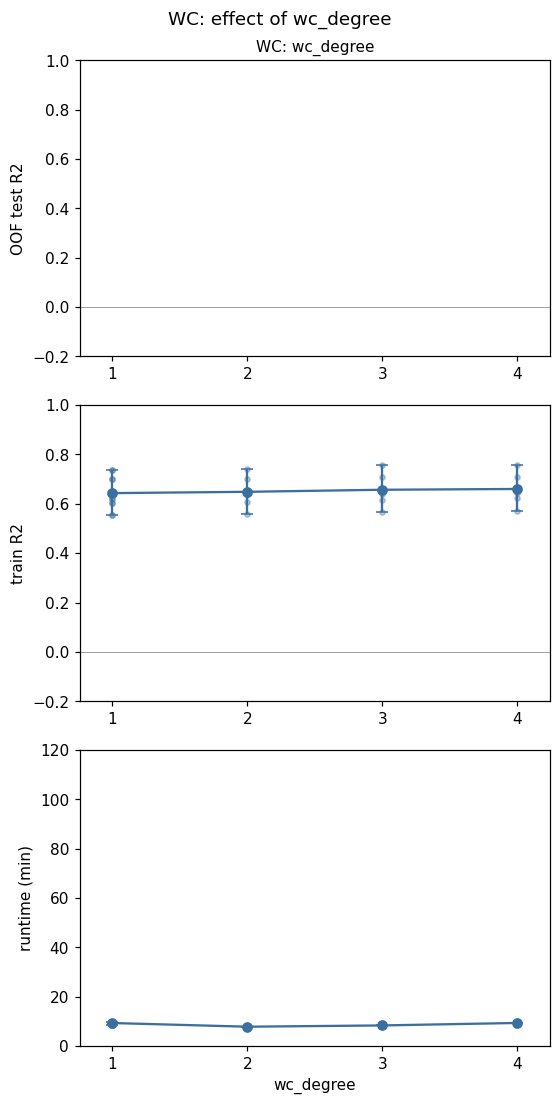

In [6]:
panel_grid([{"model": "WC", "x": "wc_degree", "fixed": PREPROC_DEFAULTS}],
          "WC: effect of wc_degree", "WC_degree_effect.png")

## SVR — `C` and `max_iter`

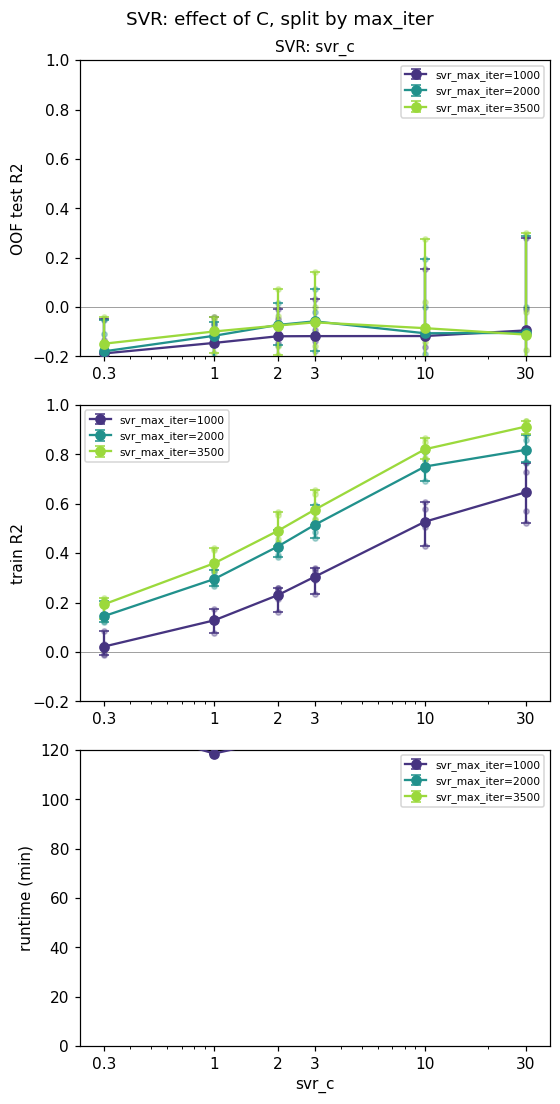

In [7]:
panel_grid([{"model": "SVR", "x": "svr_c", "hue": "svr_max_iter", "fixed": PREPROC_DEFAULTS}],
          "SVR: effect of C, split by max_iter", "SVR_C_by_maxiter.png", logx=True)

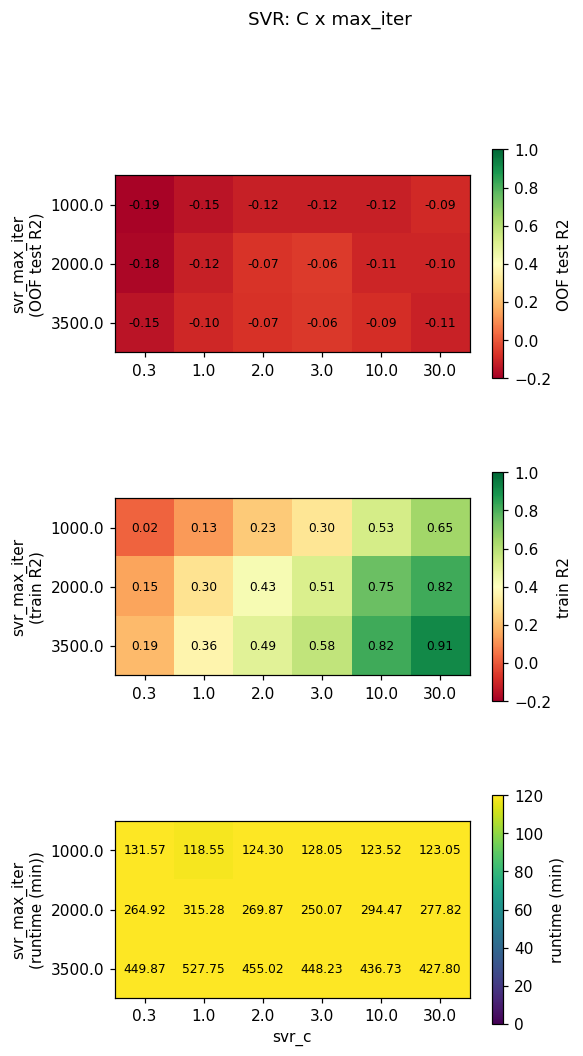

In [8]:
heatmap_grid("SVR", "svr_c", "svr_max_iter", [("", PREPROC_DEFAULTS)],
            "SVR: C x max_iter", "SVR_heatmap.png")

## XGB — `max_depth`, `n_estimators`, `learning_rate`

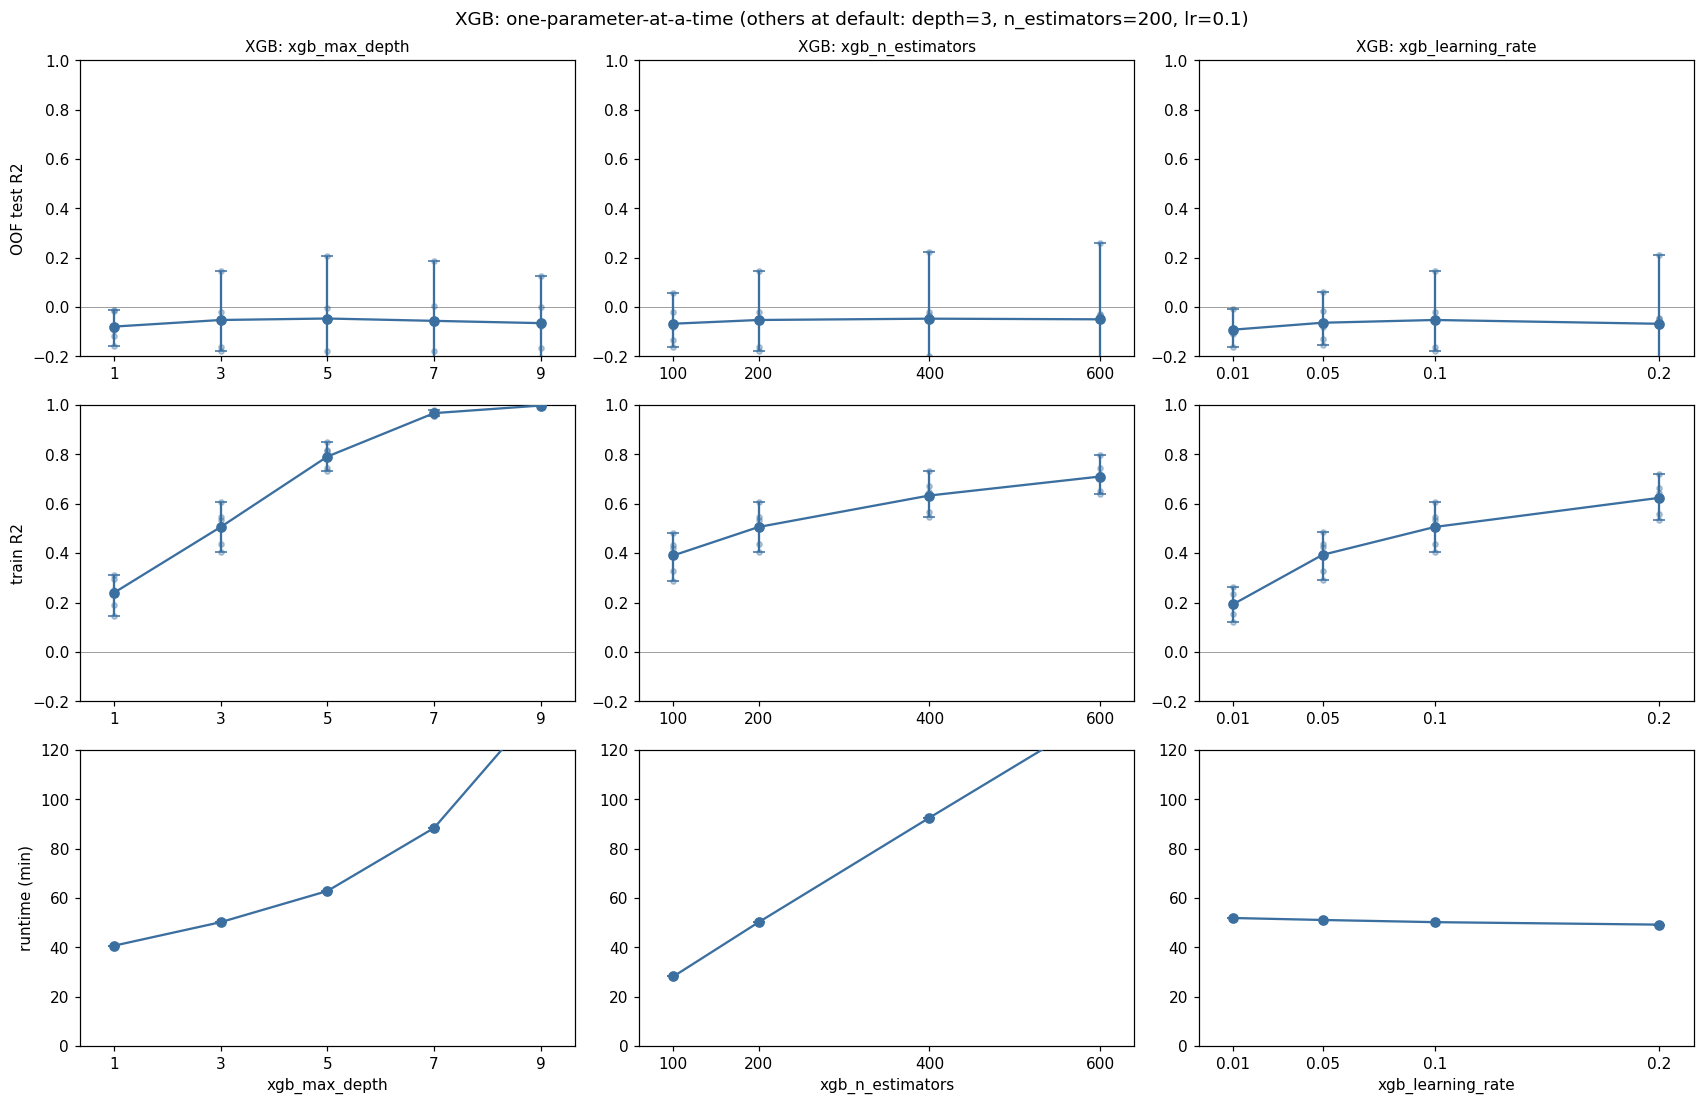

In [9]:
xgb_default = MODEL_DEFAULTS["XGB"]
xgb_specs = [
    {"model": "XGB", "x": "xgb_max_depth",
     "fixed": {"xgb_n_estimators": xgb_default["xgb_n_estimators"], "xgb_learning_rate": xgb_default["xgb_learning_rate"], **PREPROC_DEFAULTS}},
    {"model": "XGB", "x": "xgb_n_estimators",
     "fixed": {"xgb_max_depth": xgb_default["xgb_max_depth"], "xgb_learning_rate": xgb_default["xgb_learning_rate"], **PREPROC_DEFAULTS}},
    {"model": "XGB", "x": "xgb_learning_rate",
     "fixed": {"xgb_max_depth": xgb_default["xgb_max_depth"], "xgb_n_estimators": xgb_default["xgb_n_estimators"], **PREPROC_DEFAULTS}},
]
panel_grid(xgb_specs, "XGB: one-parameter-at-a-time (others at default: depth=3, n_estimators=200, lr=0.1)",
          "XGB_marginals.png")

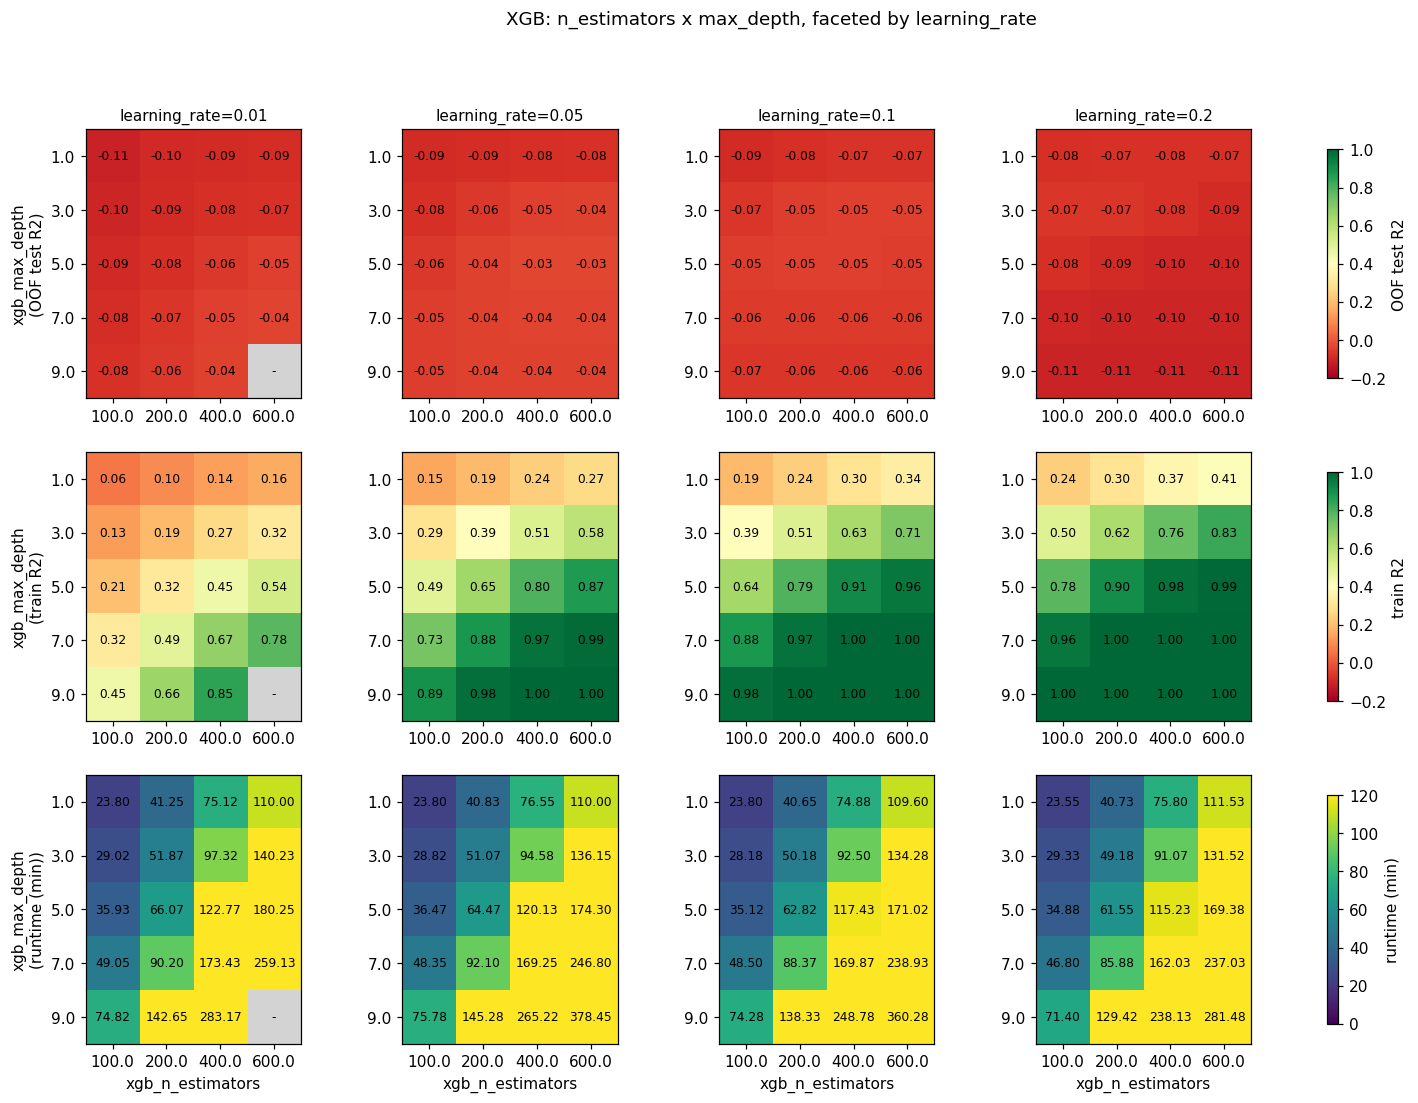

In [10]:
lrs = sorted(df.loc[df.model == "XGB", "xgb_learning_rate"].dropna().unique())
facets = [(f"learning_rate={lr:g}", {"xgb_learning_rate": lr, **PREPROC_DEFAULTS}) for lr in lrs]
heatmap_grid("XGB", "xgb_n_estimators", "xgb_max_depth", facets,
            "XGB: n_estimators x max_depth, faceted by learning_rate", "XGB_heatmap_by_lr.png")

## GPU models — FNN / RNN / GRU / LSTM

Same style as the CPU models above -- coverage depends on how far the
GPU sweep has progressed for whichever `SEARCH_ROOT` is set above; panels
print "[no data yet]" for any hyperparameter value not yet completed.

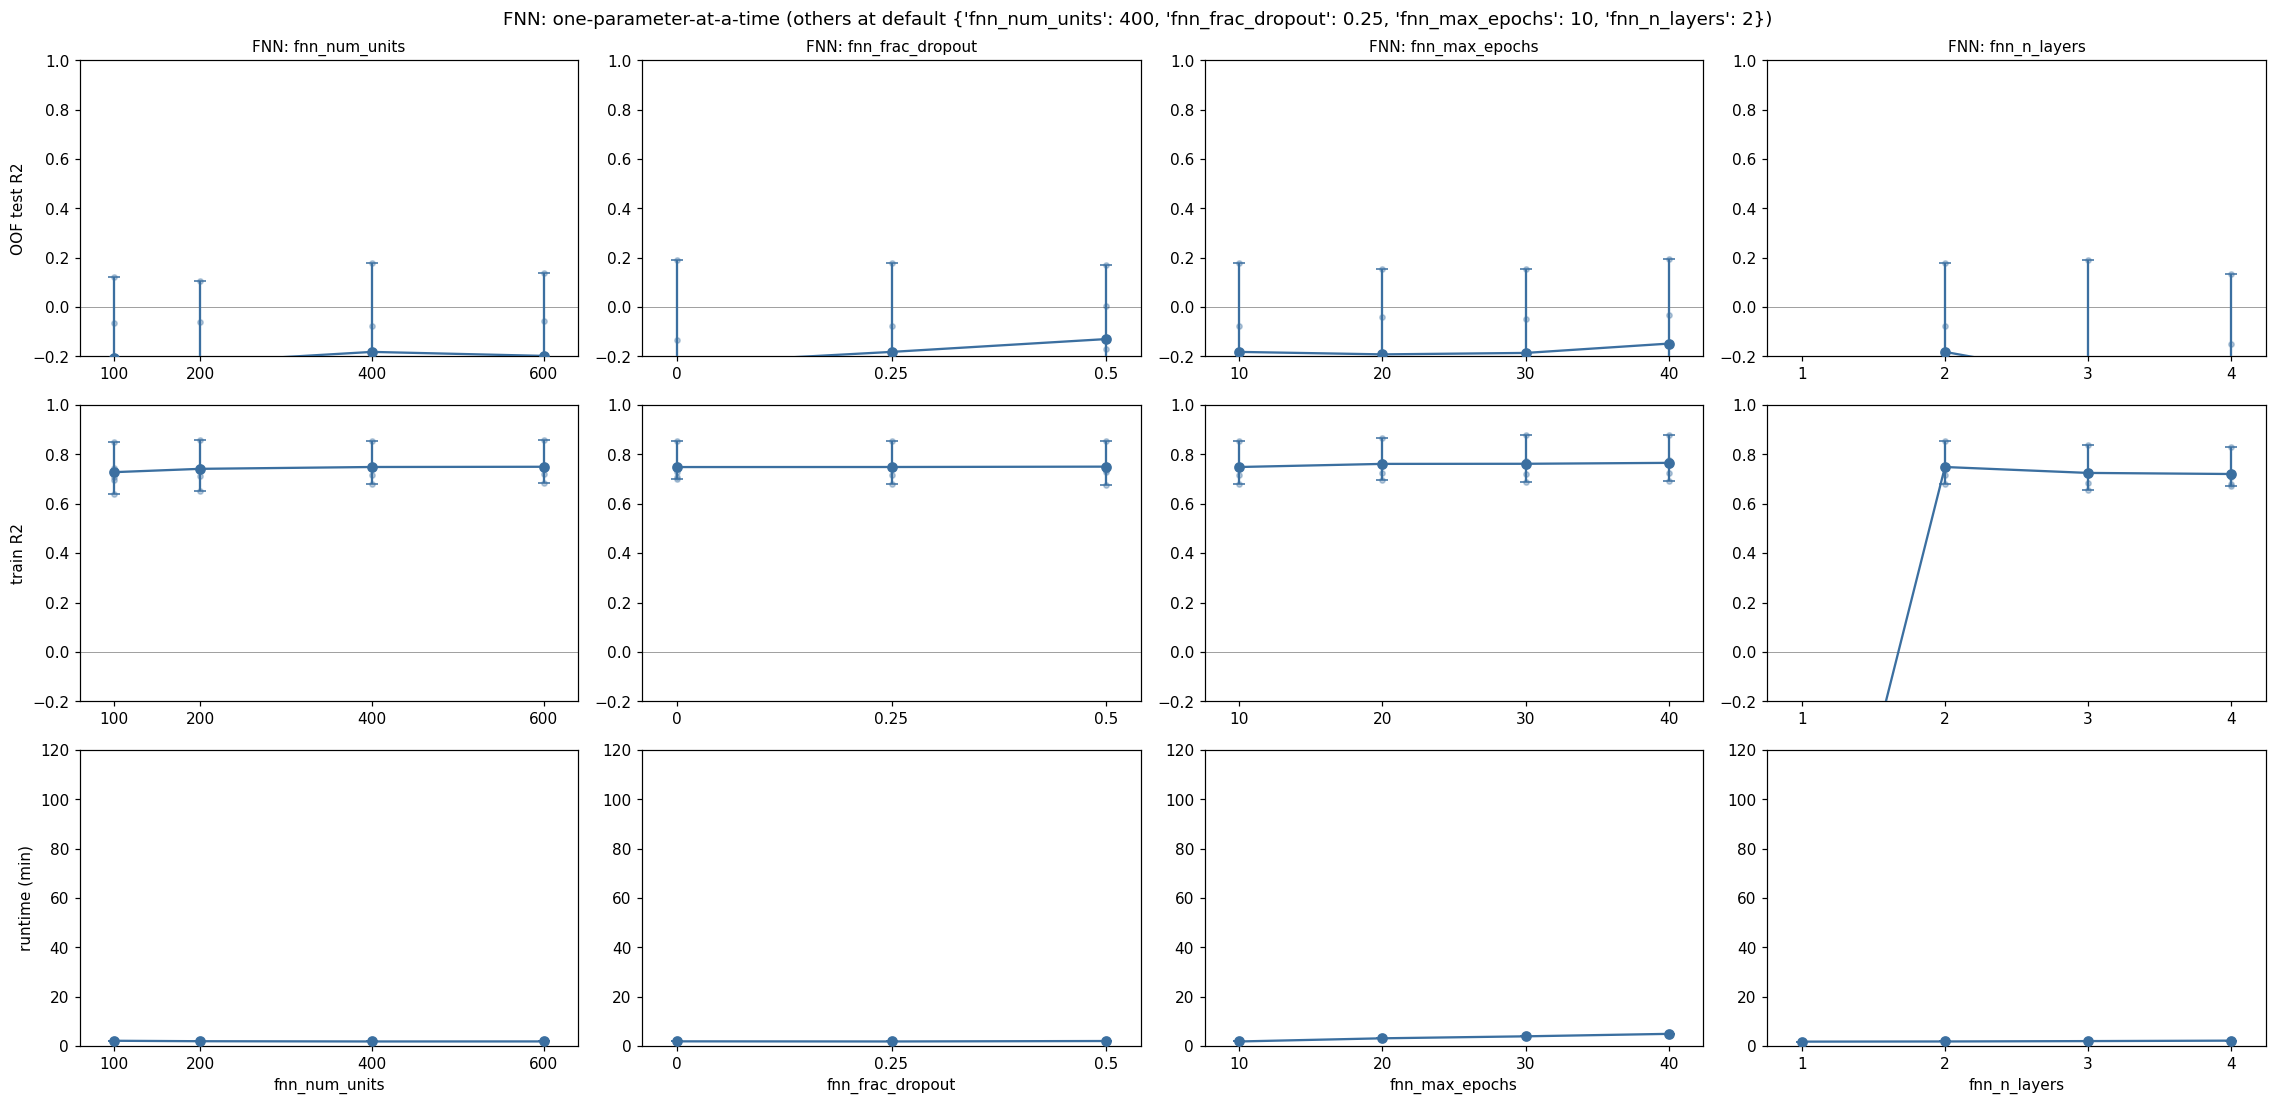

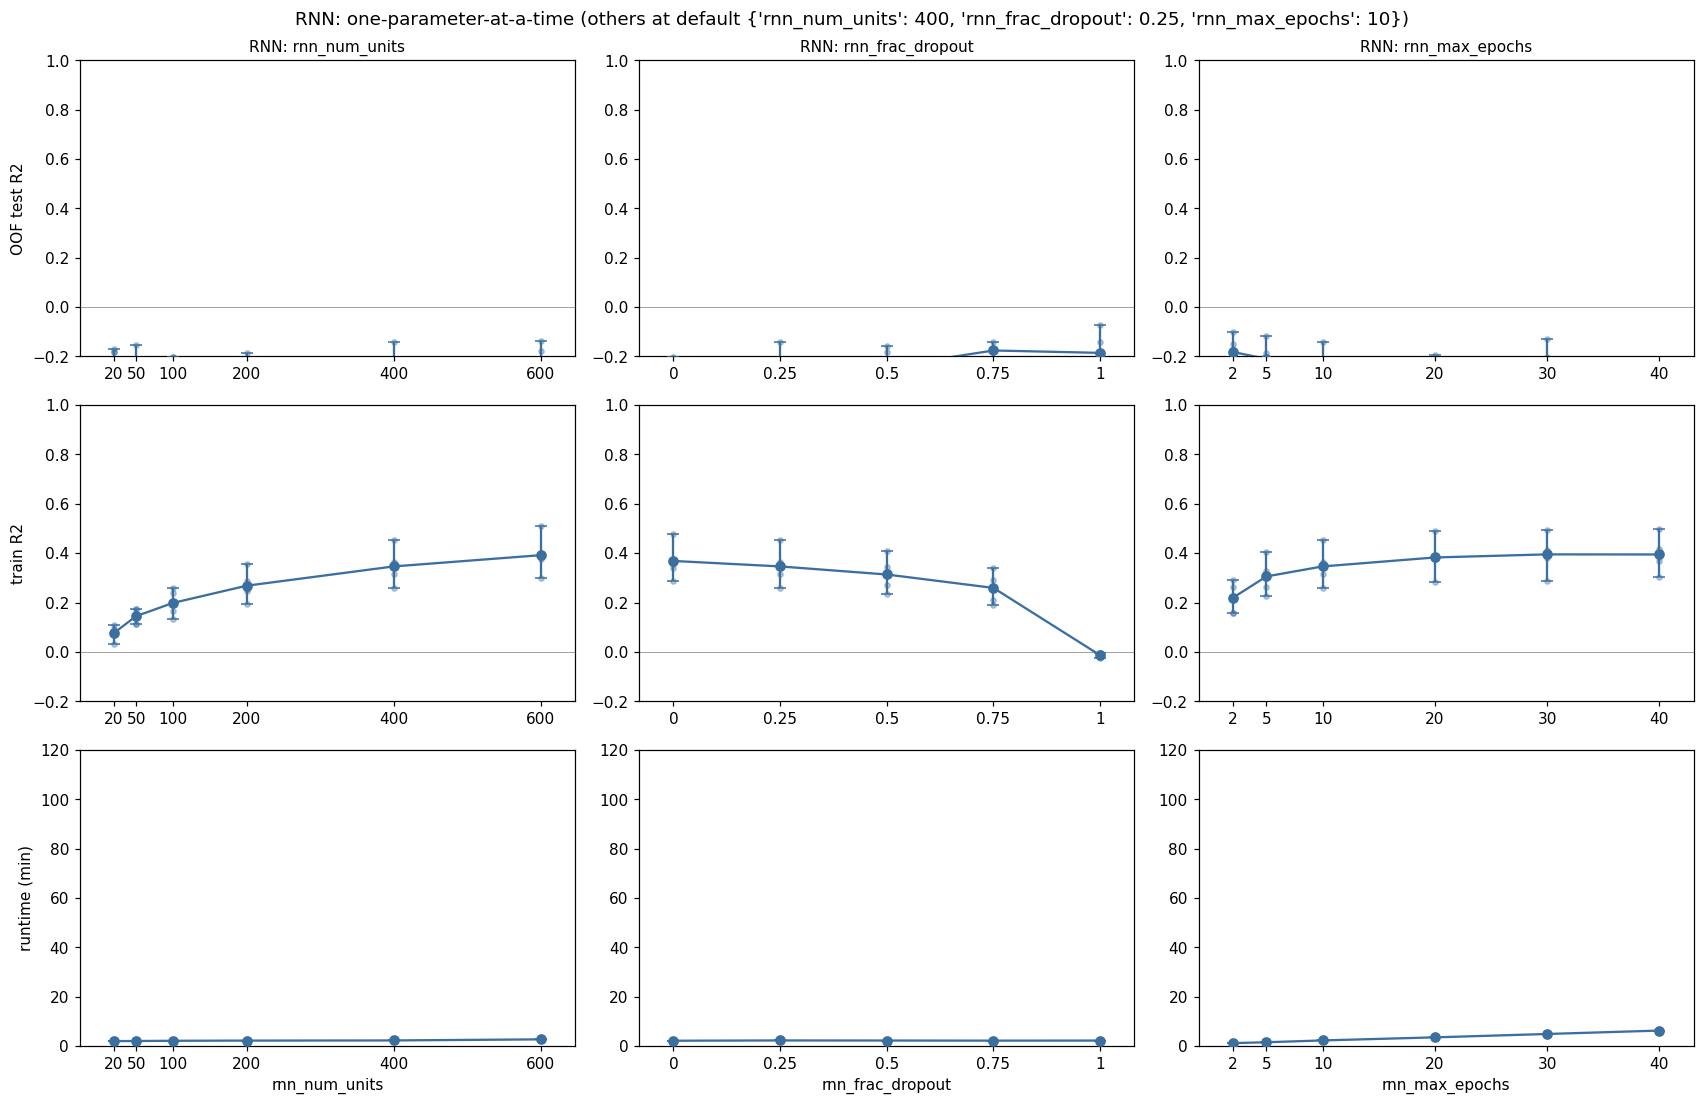

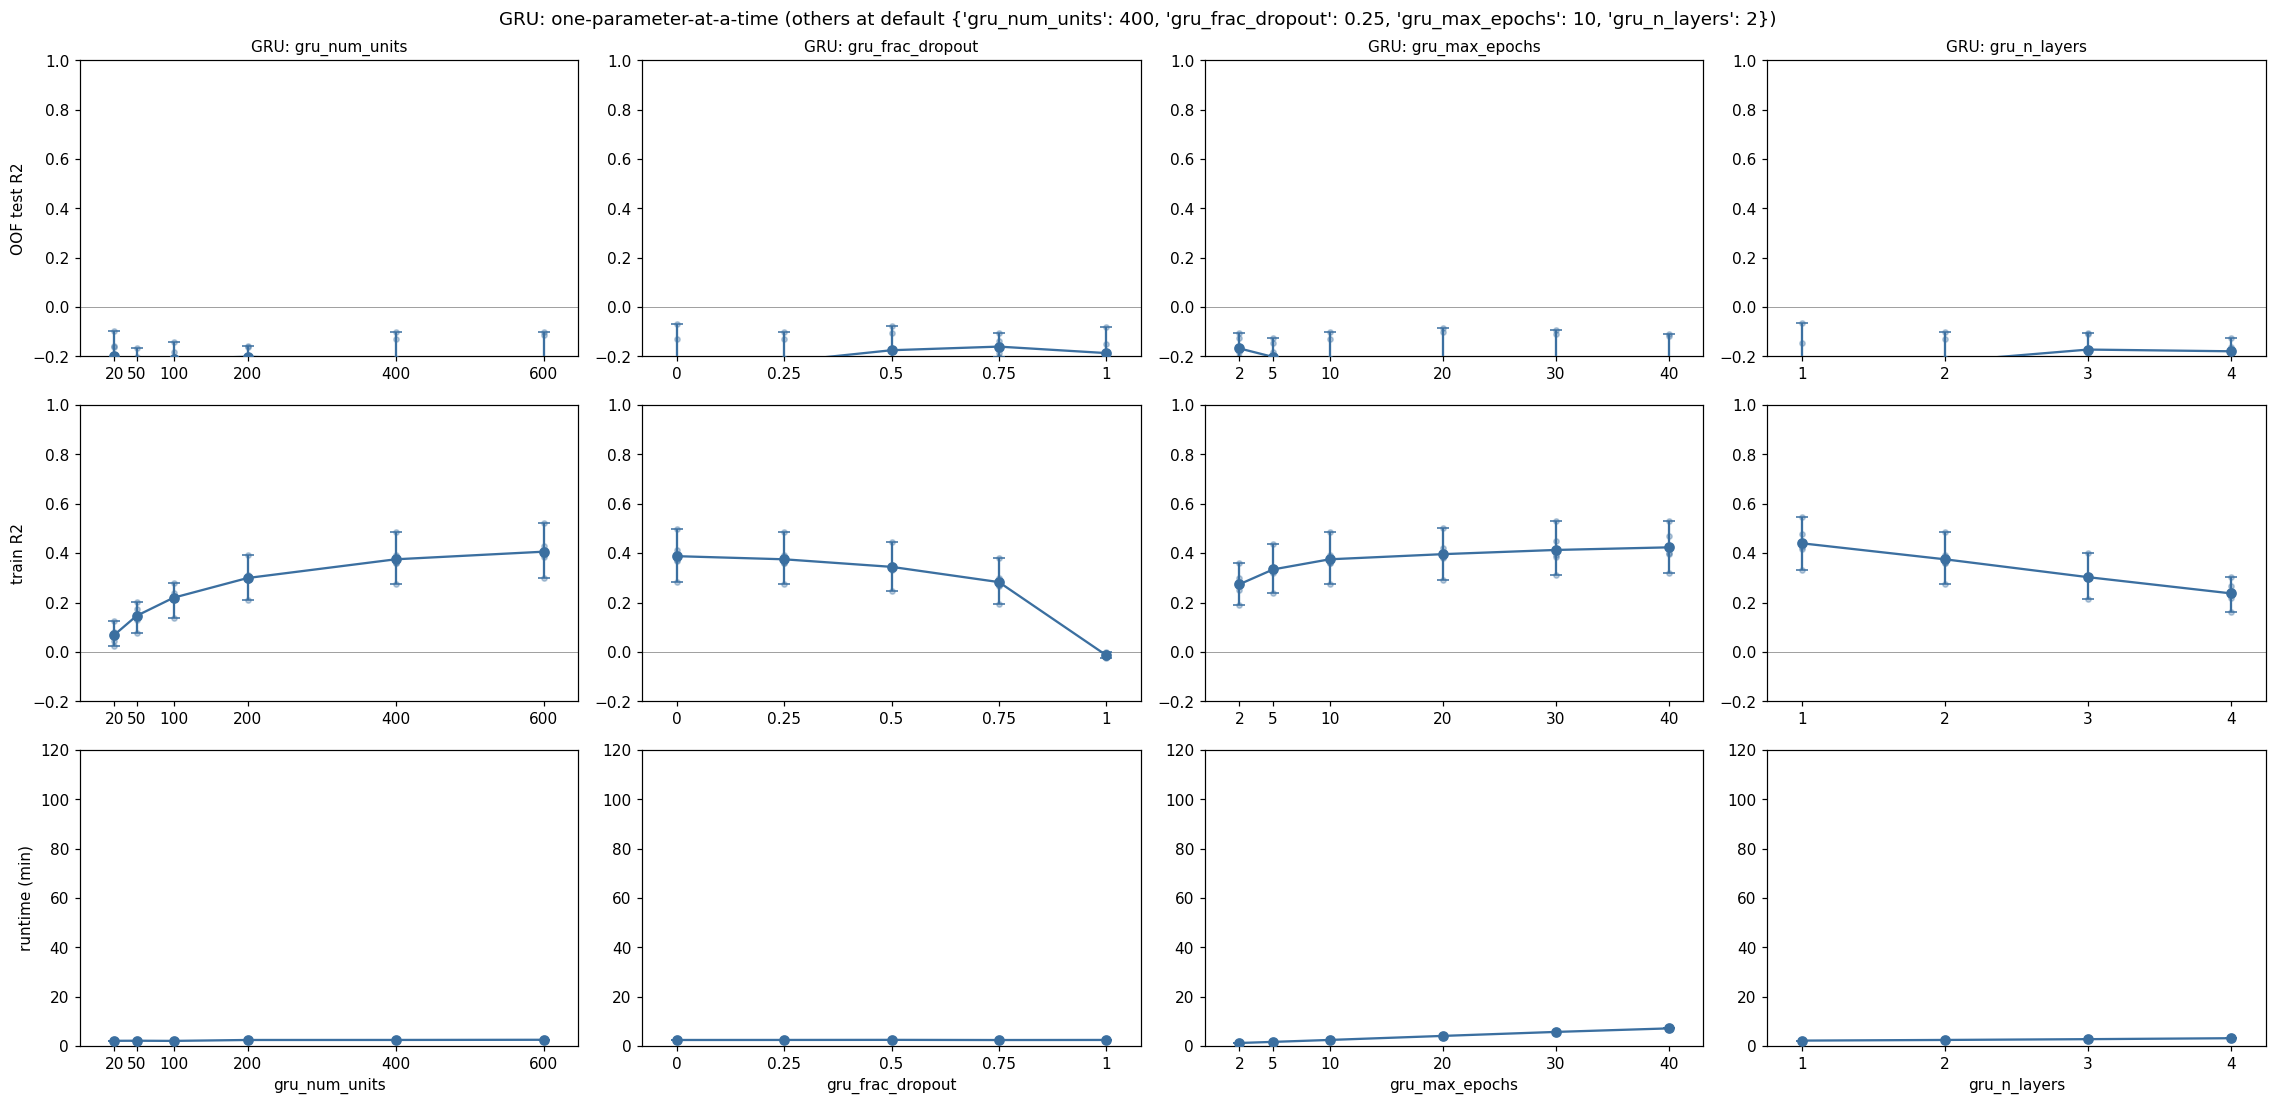

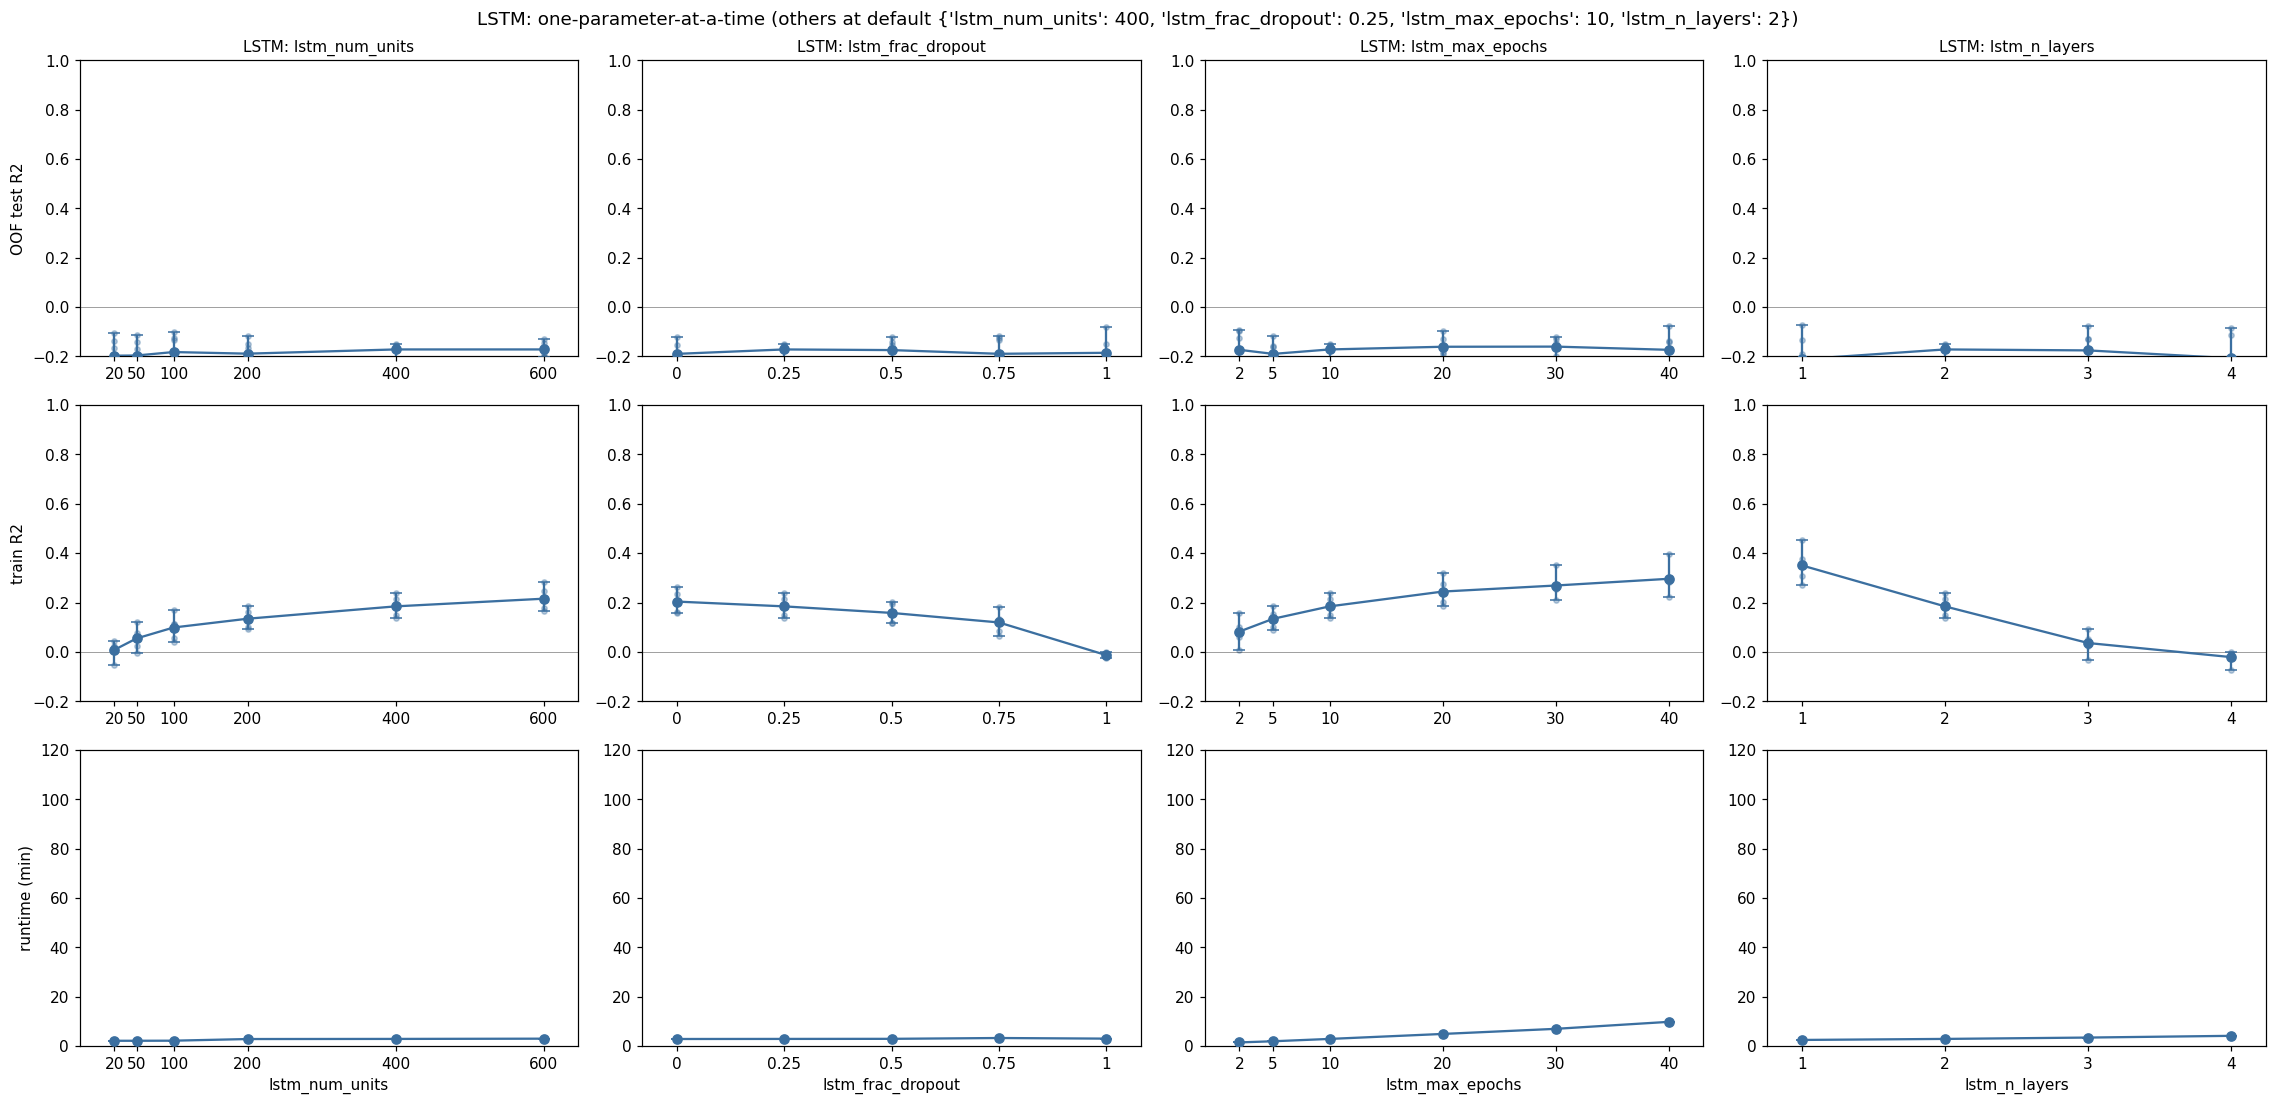

In [11]:
for model in GPU_MODELS:
    n = df.loc[df.model == model, "run_dir"].nunique()
    if n == 0:
        print(f"{model}: no completed runs yet.")
        continue
    hp_cols = MODEL_HP_COLS[model]
    default = MODEL_DEFAULTS[model]
    specs = []
    for hp in hp_cols:
        other = {k: v for k, v in default.items() if k != hp}
        specs.append({"model": model, "x": hp, "fixed": {**other, **PREPROC_DEFAULTS}})
    panel_grid(specs, f"{model}: one-parameter-at-a-time (others at default {default})",
              f"{model}_marginals.png")

### GPU models — full grid heatmaps

Same treatment as XGB above: the complete `num_units x max_epochs` grid,
faceted by `frac_dropout`, so no combination is hidden behind a
one-parameter-at-a-time slice.

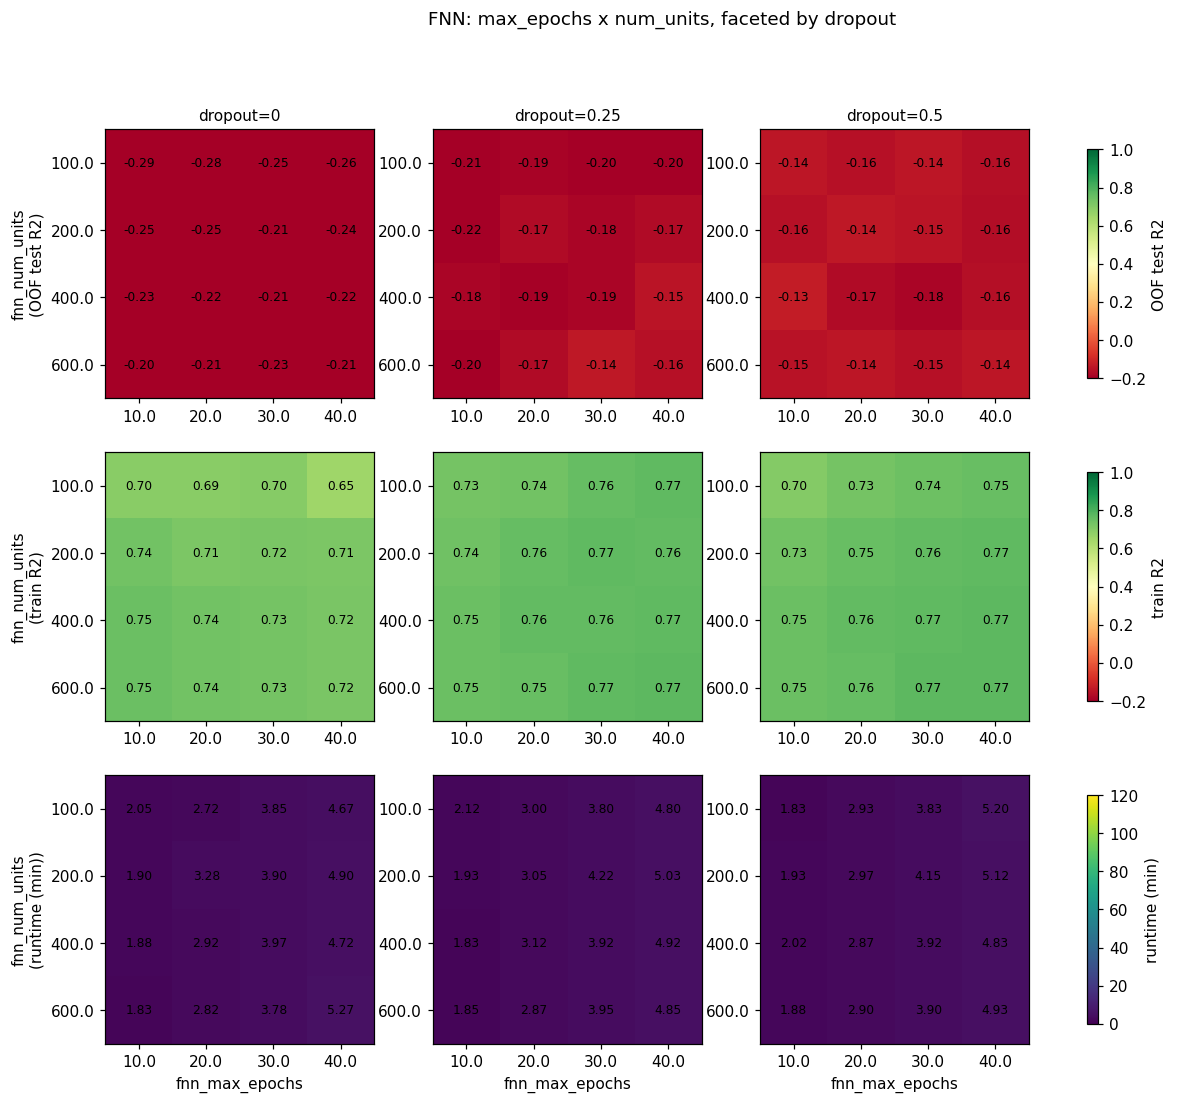

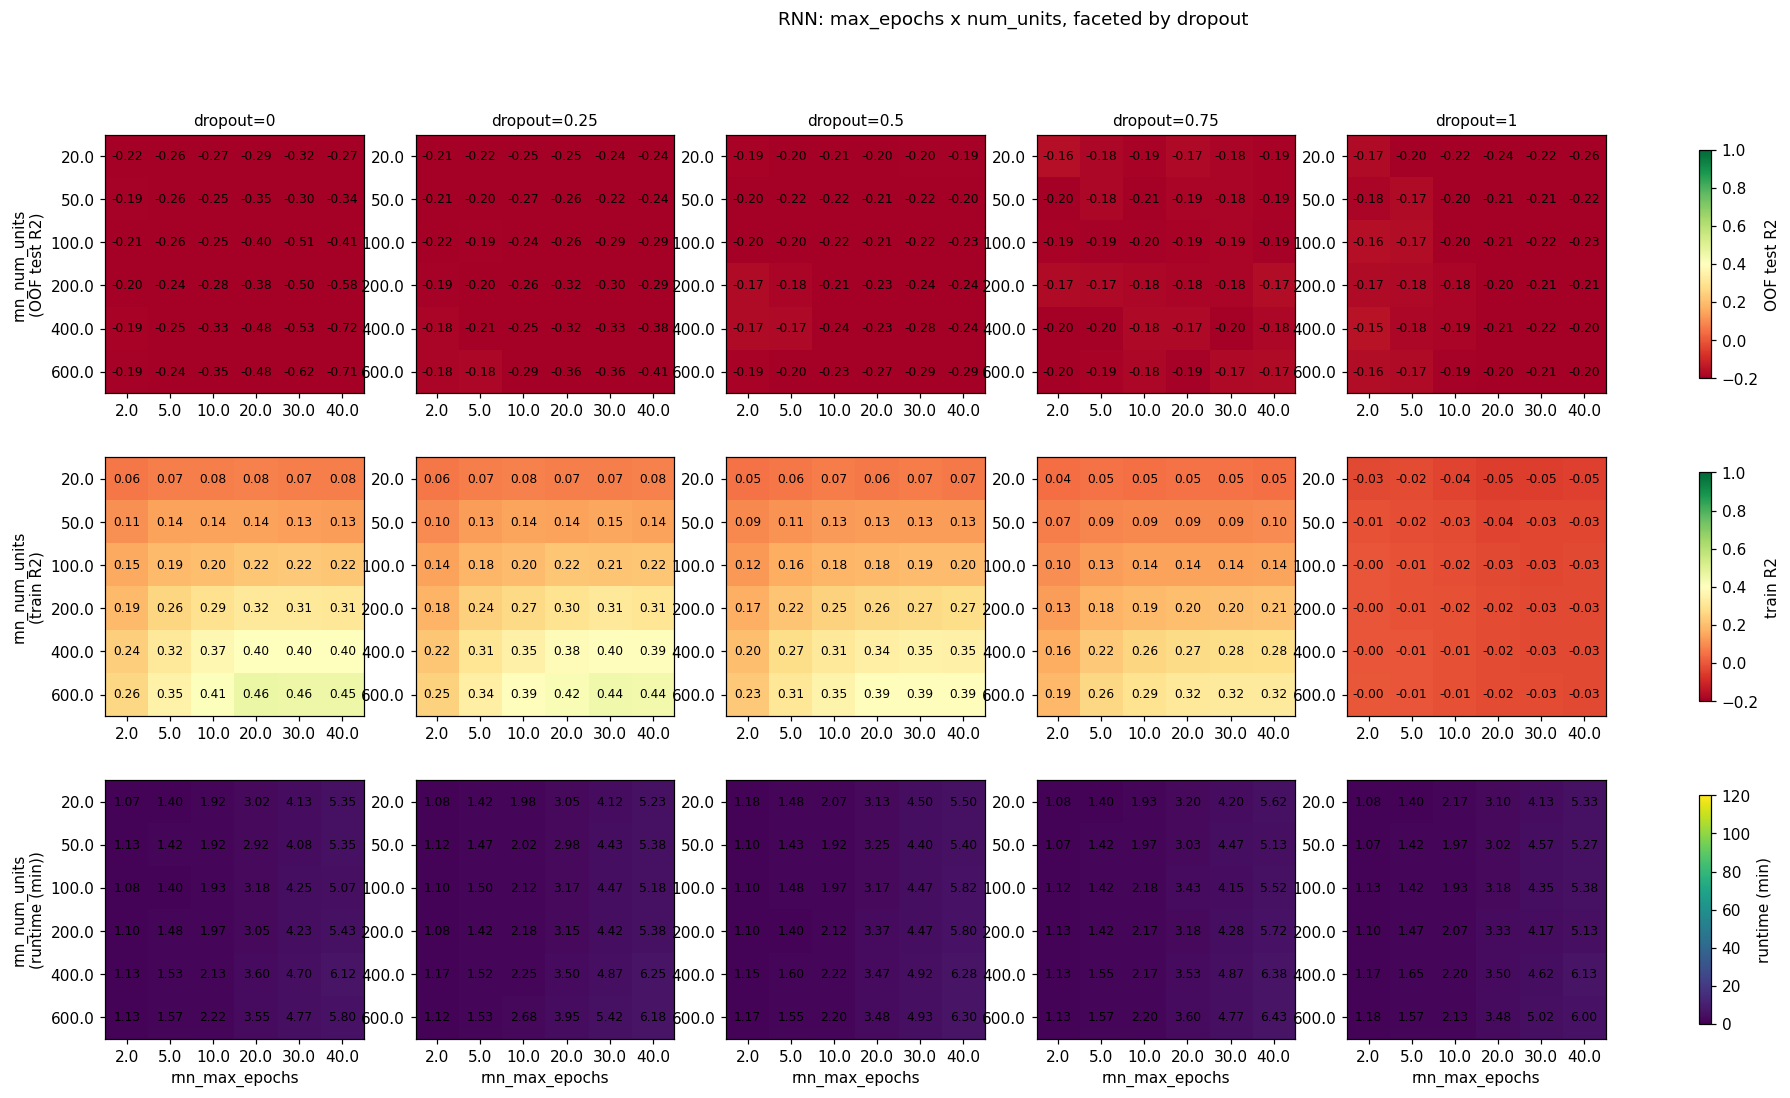

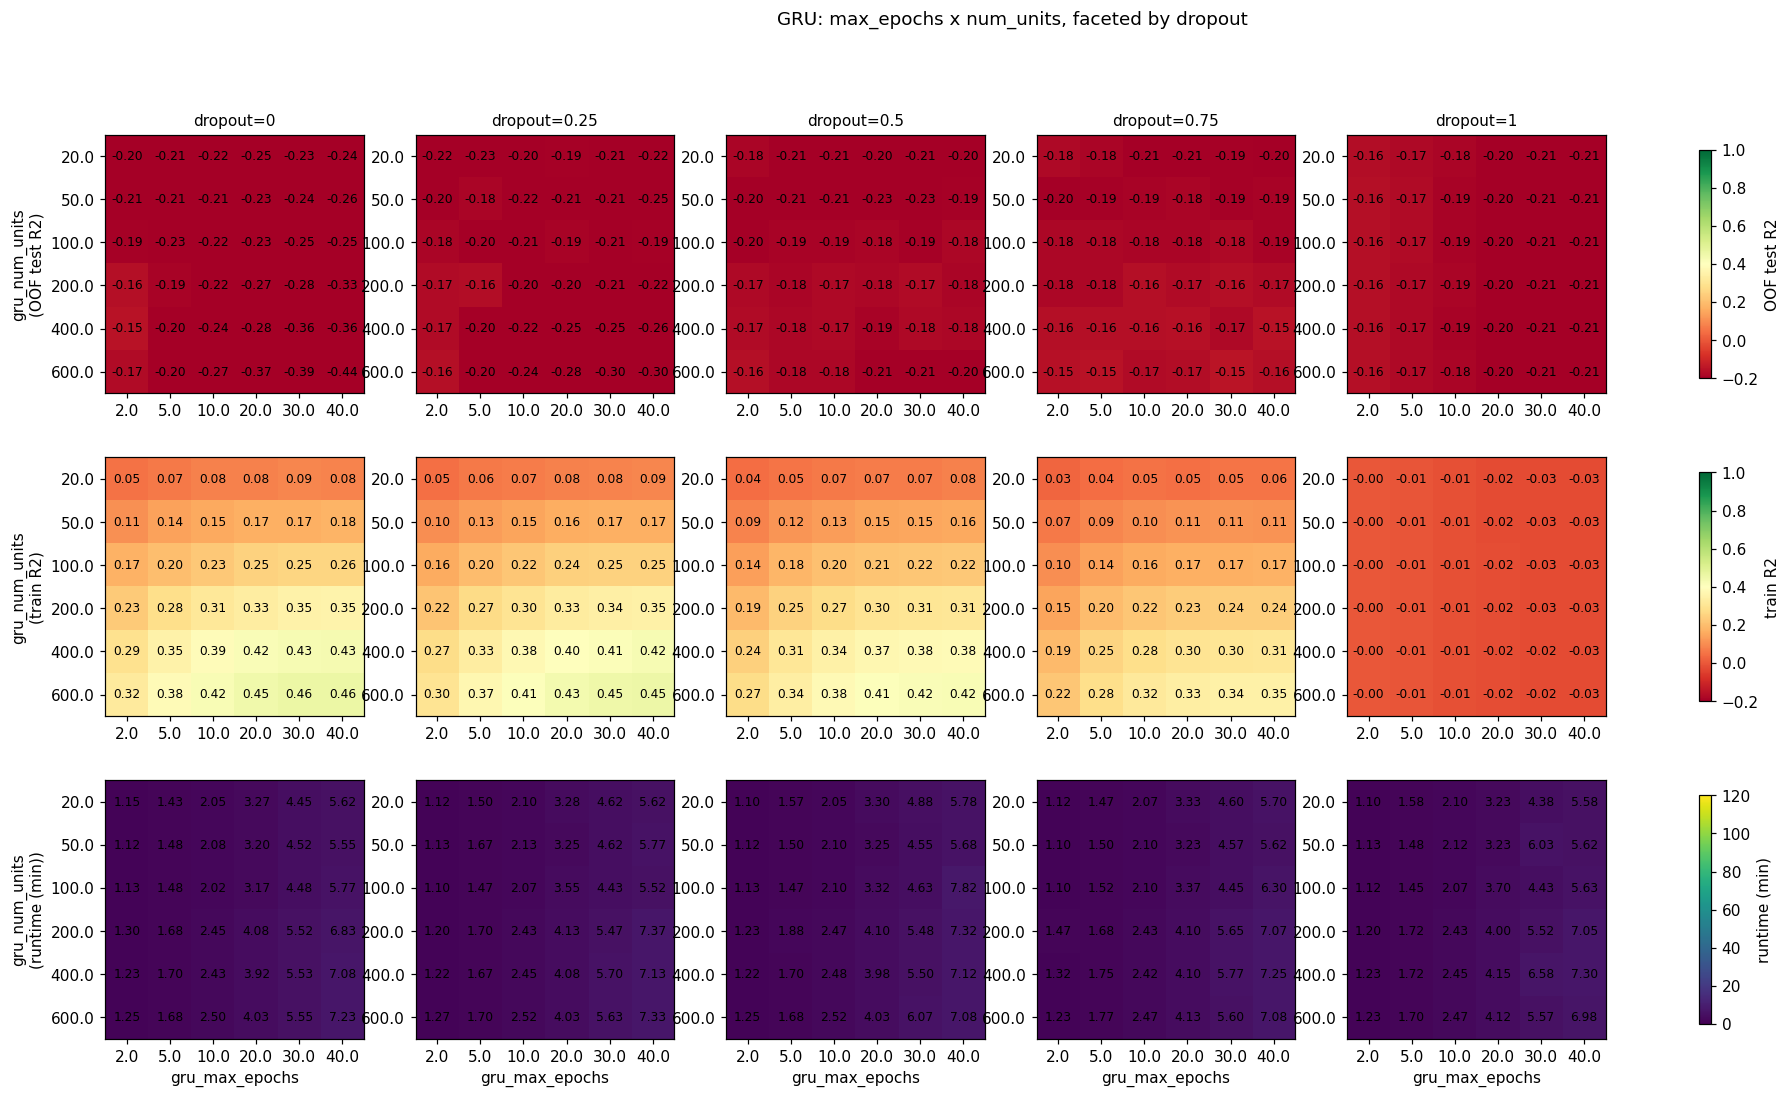

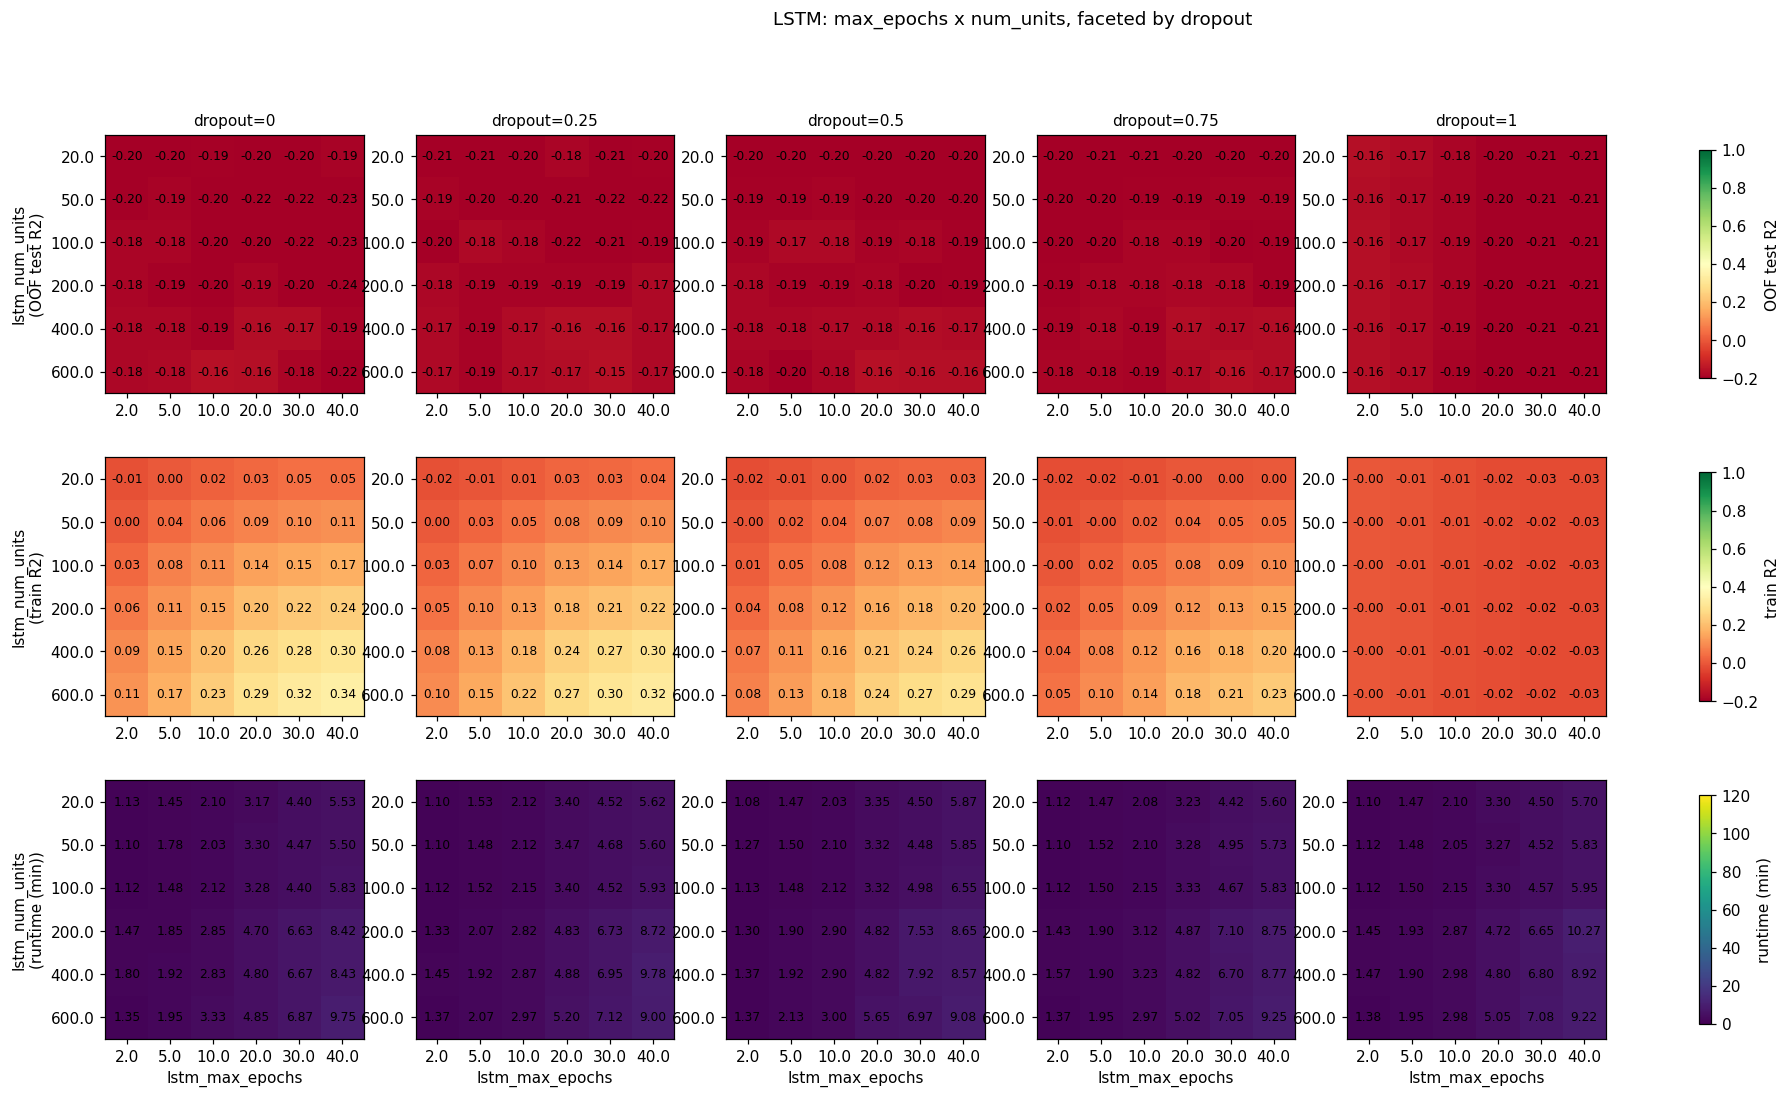

In [12]:
for model in GPU_MODELS:
    if df.loc[df.model == model, "run_dir"].nunique() == 0:
        print(f"{model}: no completed runs yet.")
        continue
    prefix = model.lower()
    hp_x, hp_y, facet_col = f"{prefix}_max_epochs", f"{prefix}_num_units", f"{prefix}_frac_dropout"
    # Pin any other hyperparameter this model has (e.g. n_layers for FNN/GRU/LSTM,
    # nothing extra for RNN) at its default -- otherwise it'd silently average
    # across it within each cell instead of showing the picture at one anchor.
    other_defaults = {k: v for k, v in MODEL_DEFAULTS.get(model, {}).items() if k not in (hp_x, hp_y, facet_col)}
    facet_vals = sorted(df.loc[df.model == model, facet_col].dropna().unique())
    facets = [(f"dropout={v:g}", {facet_col: v, **other_defaults, **PREPROC_DEFAULTS}) for v in facet_vals]
    heatmap_grid(model, hp_x, hp_y, facets, f"{model}: max_epochs x num_units, faceted by dropout",
                f"{model}_heatmap_by_dropout.png")

## Preprocessing / binning sweep — `dt`, bin window, `n_splits`

Applied on top of each model's *default* hyperparameters. `bin_before`/
`bin_after` are swept together as a symmetric window, so `bin_before` stands
in for the window size below.

[no data yet] WF: dt x n_splits (oof_r2, fixed={'bin_before': 6, 'n_splits': 10, 'spike_thresh': 0})
[no data yet] WF: dt x n_splits (mean_fold_train_r2, fixed={'bin_before': 6, 'n_splits': 10, 'spike_thresh': 0})
[no data yet] WF: dt x n_splits (runtime_min, fixed={'bin_before': 6, 'n_splits': 10, 'spike_thresh': 0})


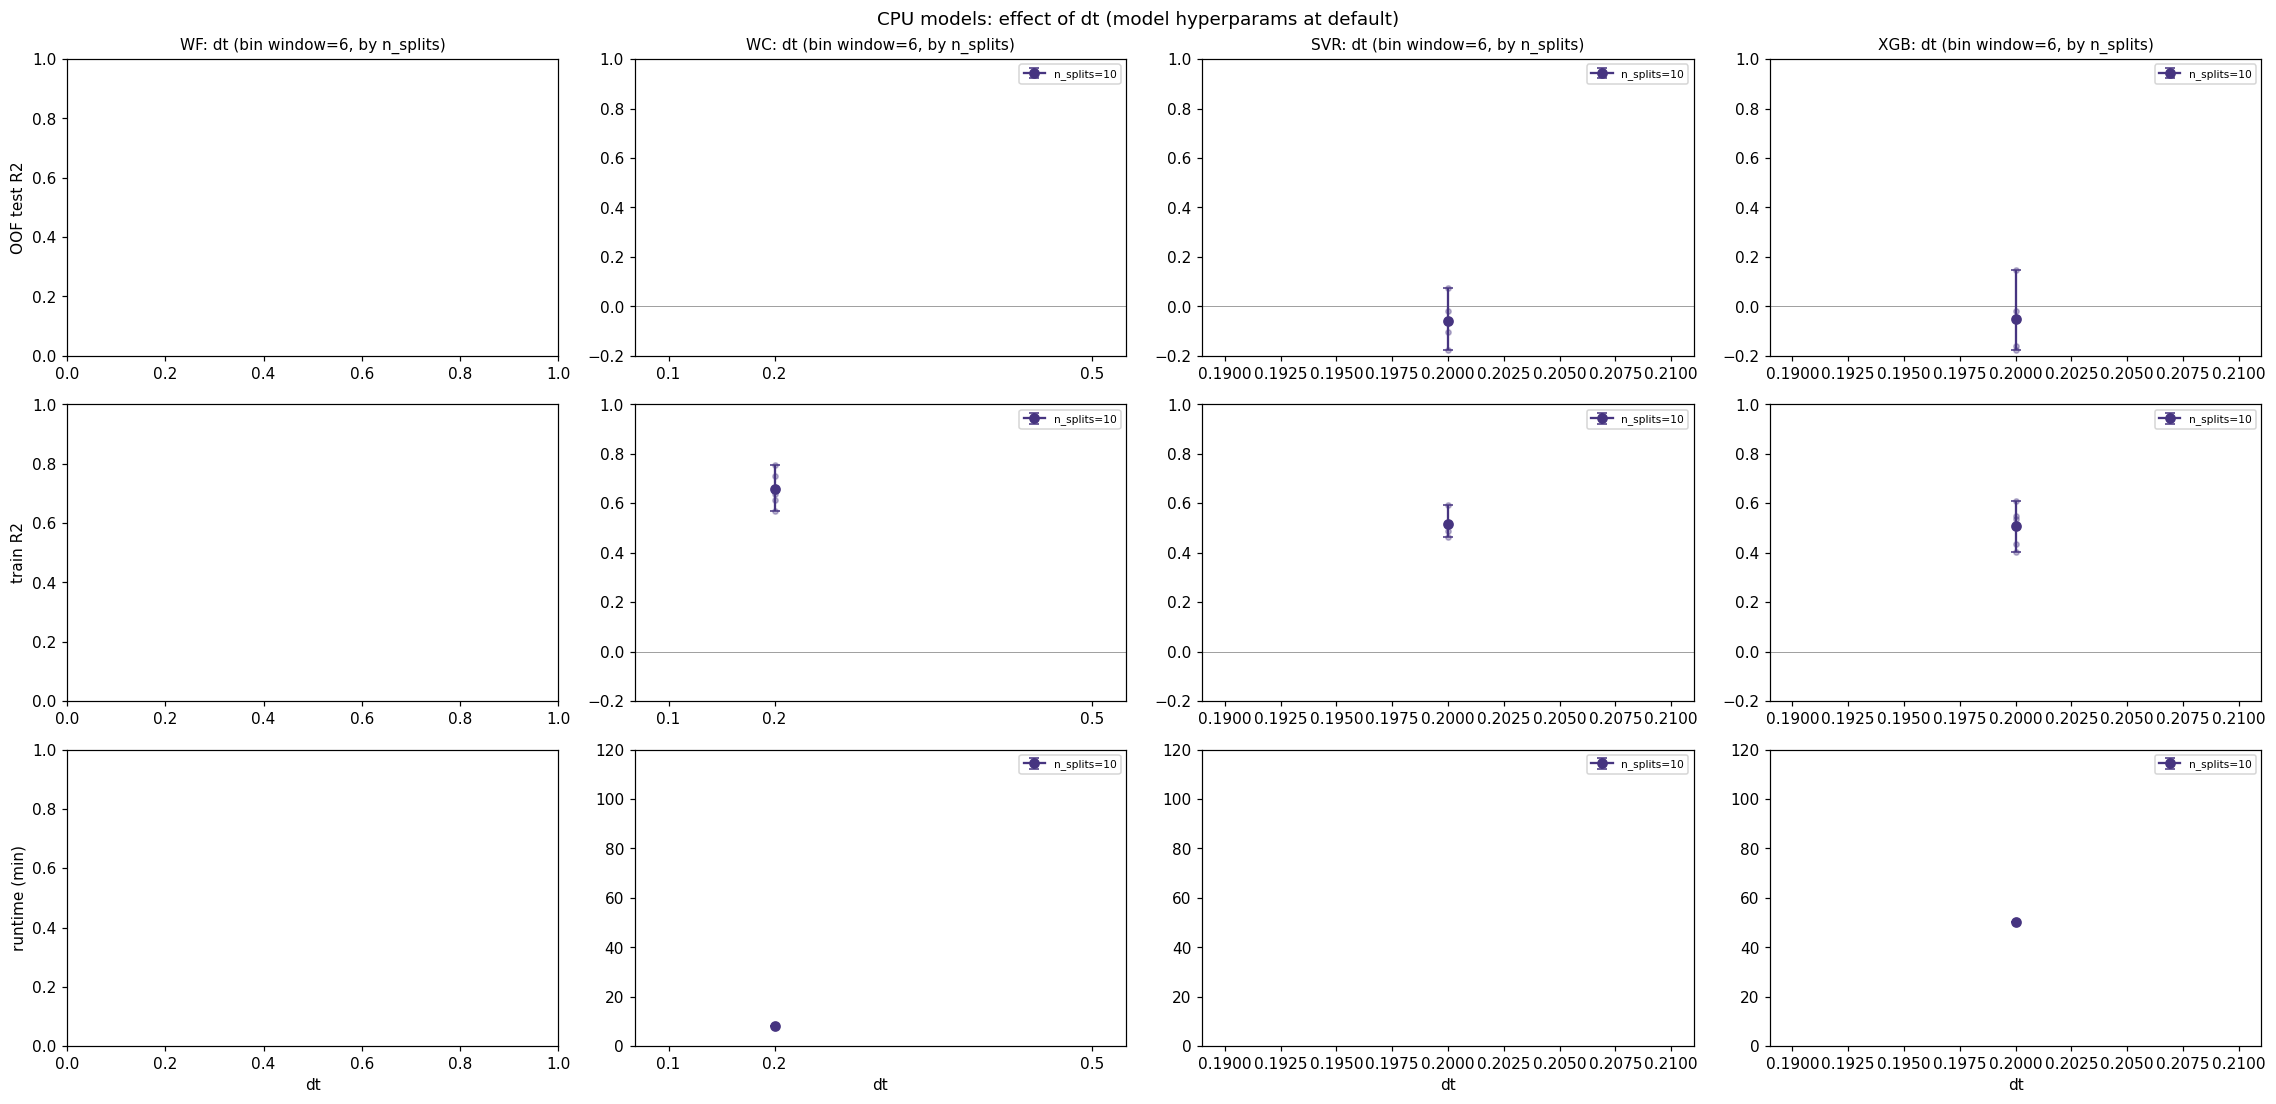

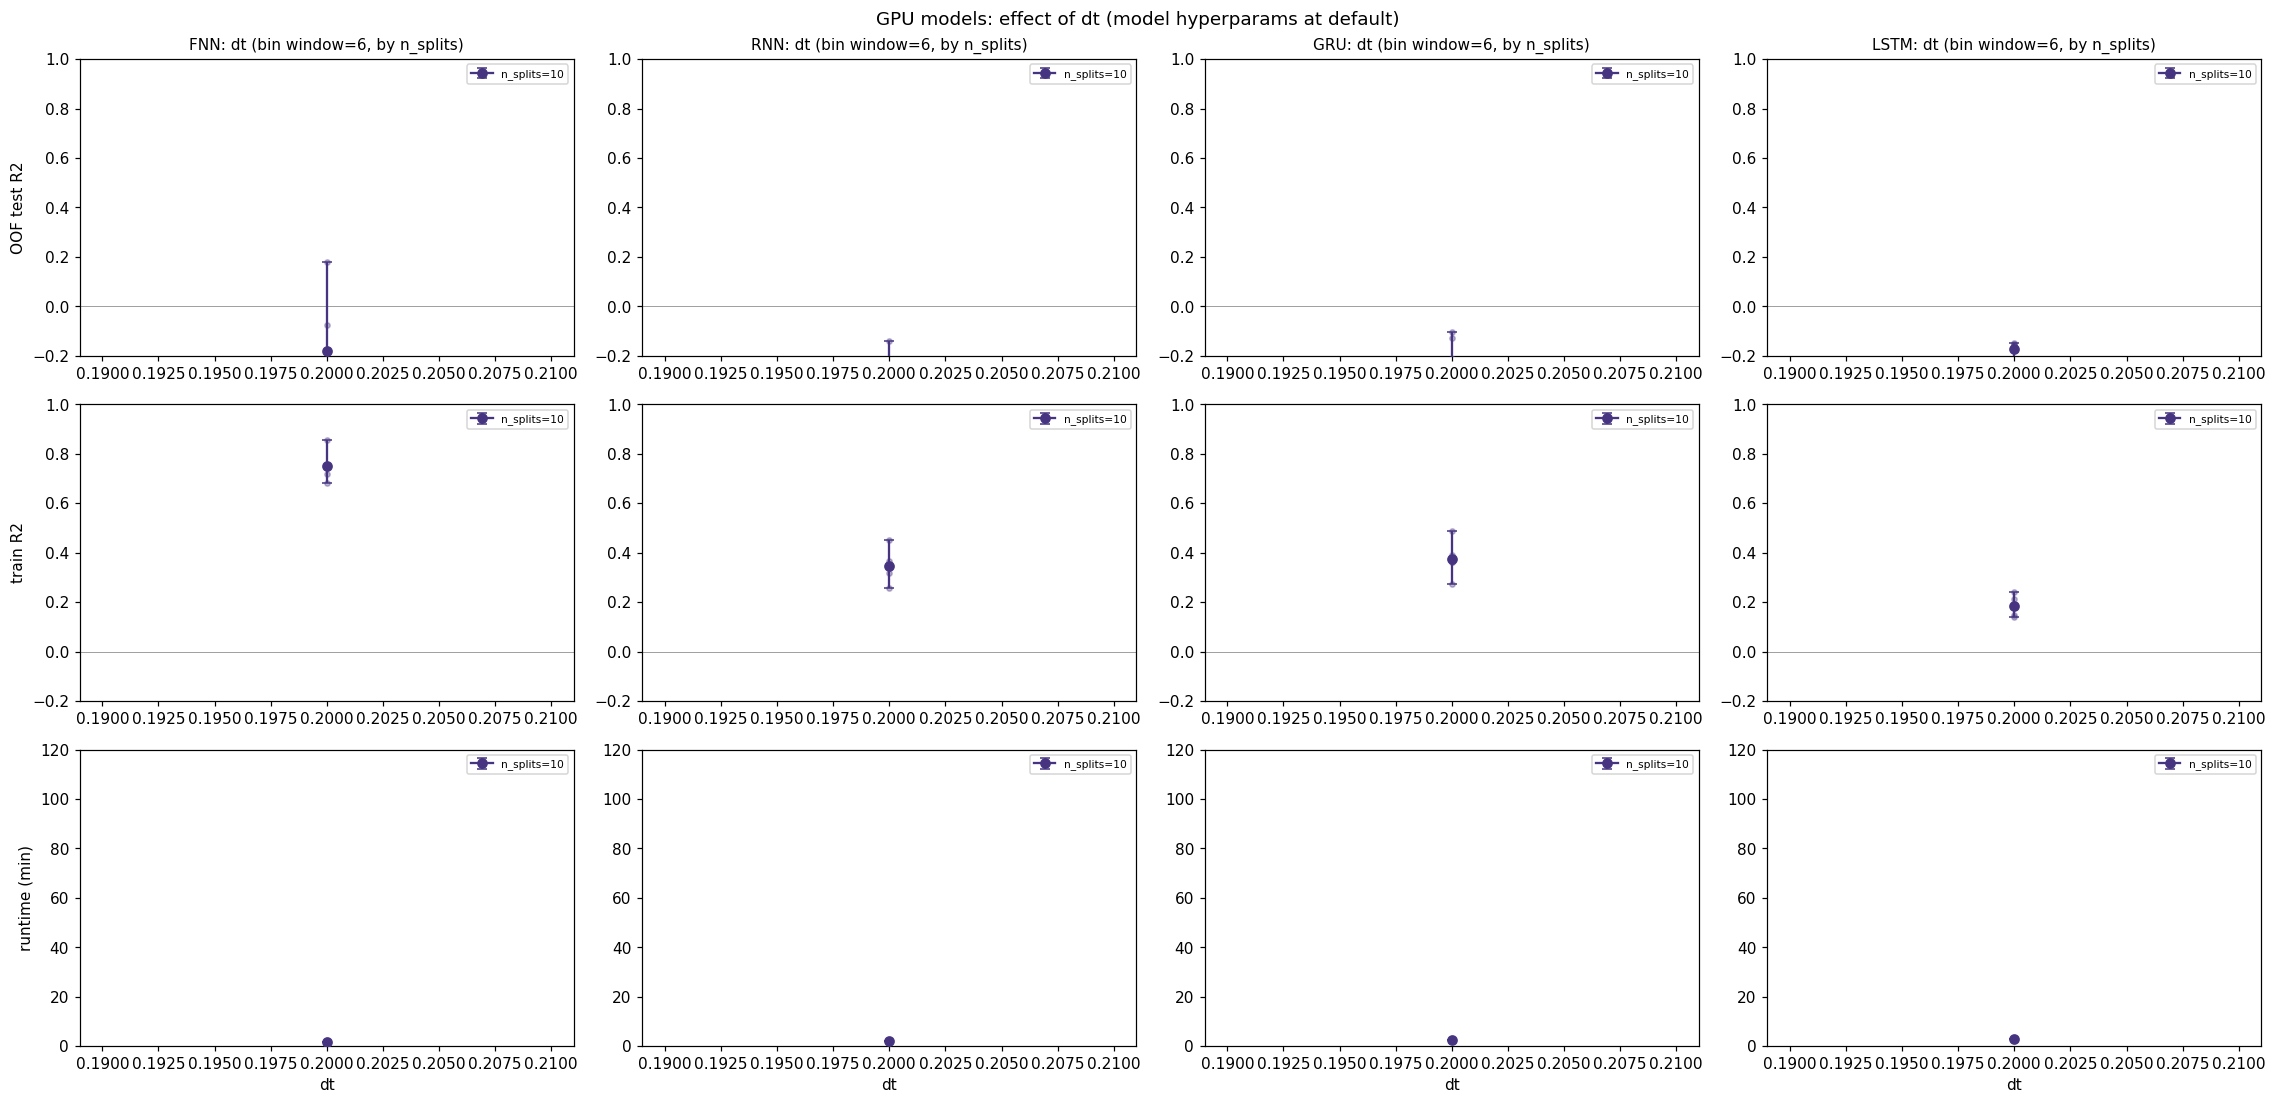

In [13]:
for group_name, models in [("CPU", CPU_MODELS), ("GPU", GPU_MODELS)]:
    specs = []
    for model in models:
        default = MODEL_DEFAULTS.get(model, {})
        fixed = {**default, "bin_before": PREPROC_DEFAULTS["bin_before"], "n_splits": PREPROC_DEFAULTS["n_splits"],
                 "spike_thresh": PREPROC_DEFAULTS["spike_thresh"]}
        specs.append({"model": model, "x": "dt", "hue": "n_splits", "fixed": fixed, "title": f"{model}: dt (bin window=6, by n_splits)"})
    panel_grid(specs, f"{group_name} models: effect of dt (model hyperparams at default)",
              f"dt_sweep_{group_name.lower()}.png")

[no data yet] WF: bin_before (oof_r2, fixed={'dt': 0.2, 'n_splits': 10, 'spike_thresh': 0})
[no data yet] WF: bin_before (mean_fold_train_r2, fixed={'dt': 0.2, 'n_splits': 10, 'spike_thresh': 0})
[no data yet] WF: bin_before (runtime_min, fixed={'dt': 0.2, 'n_splits': 10, 'spike_thresh': 0})


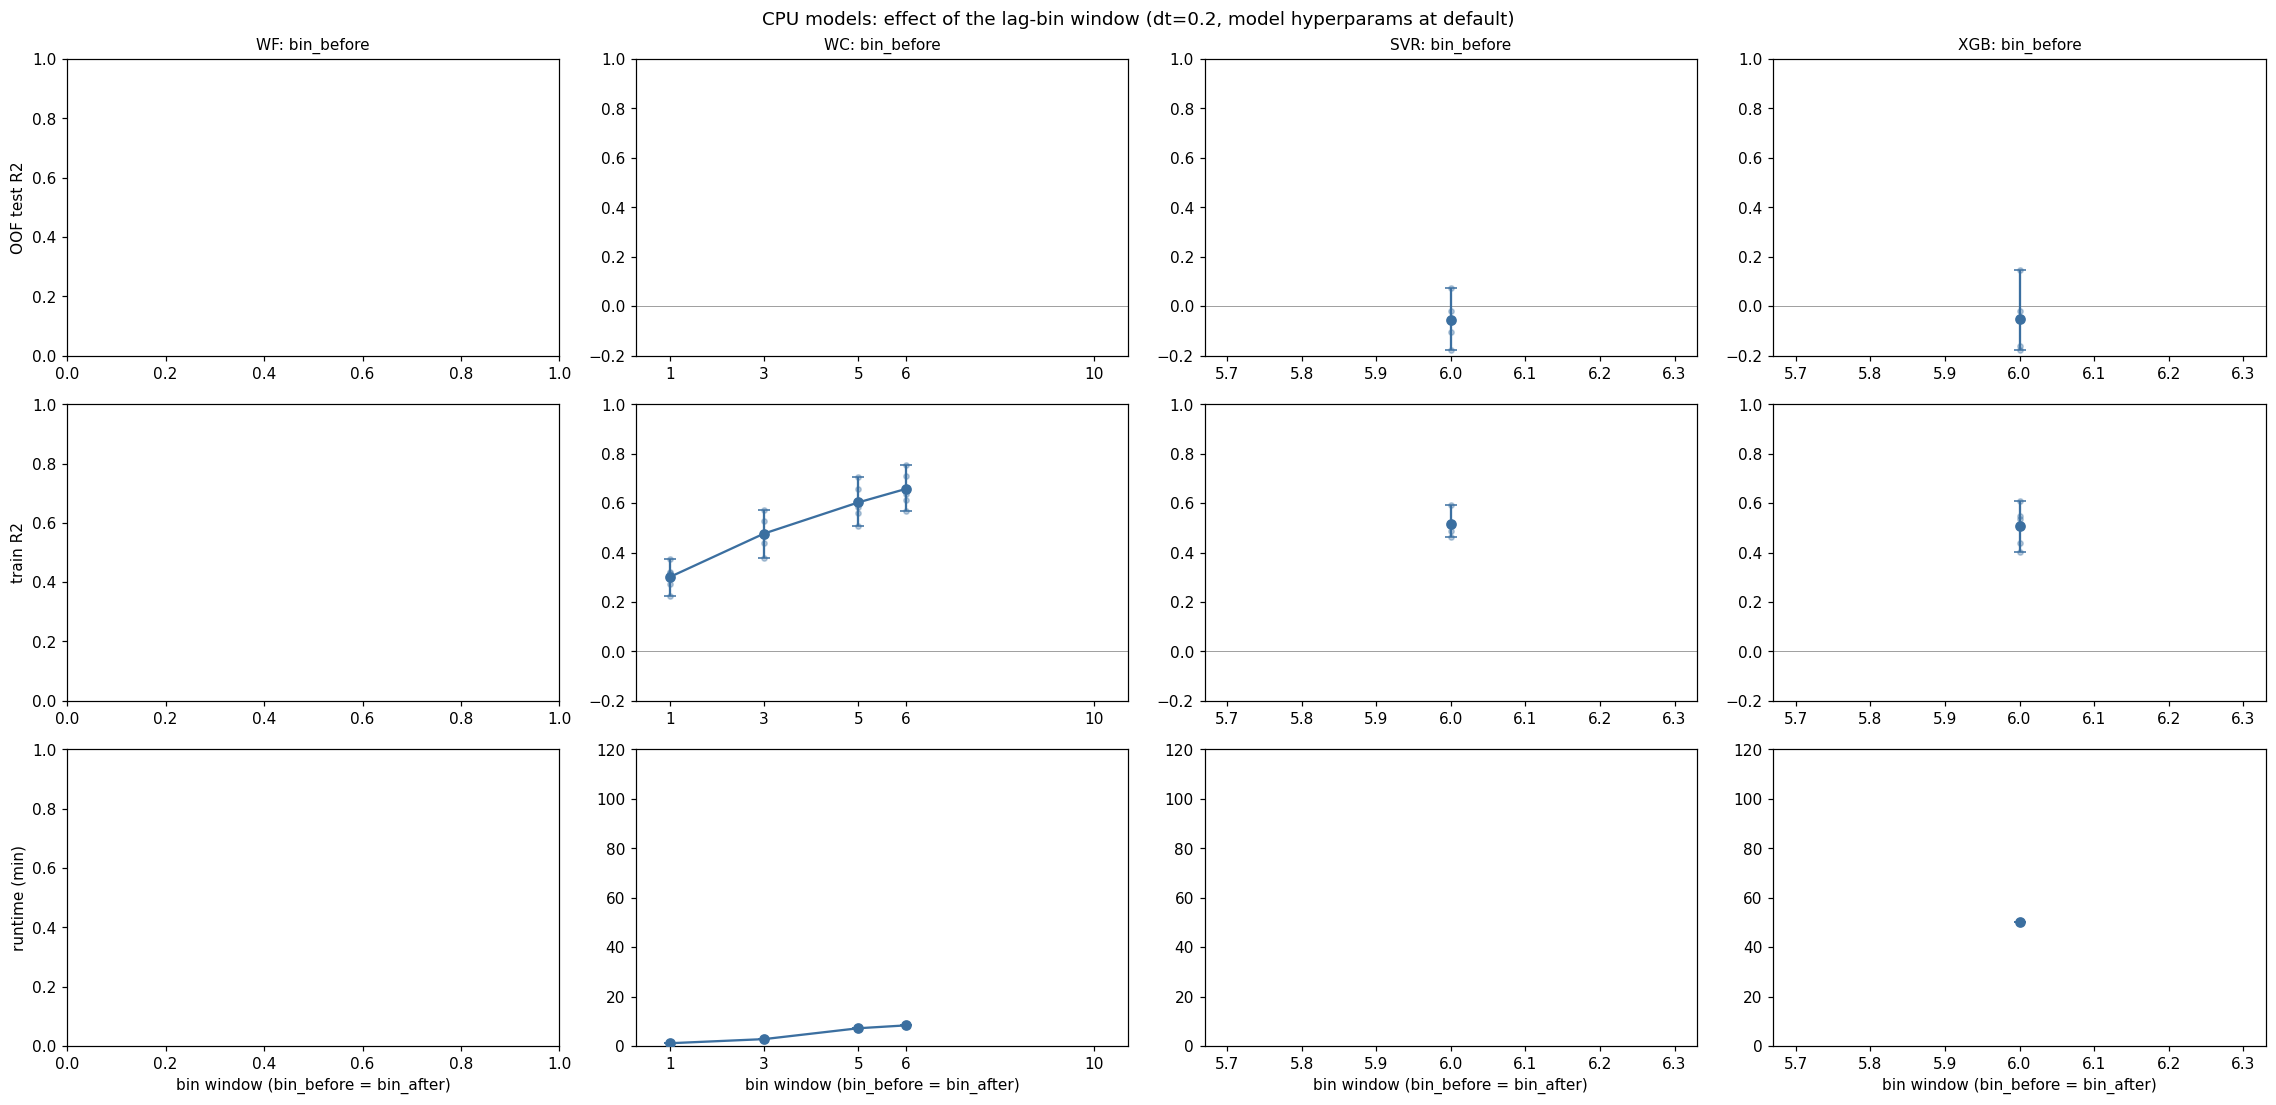

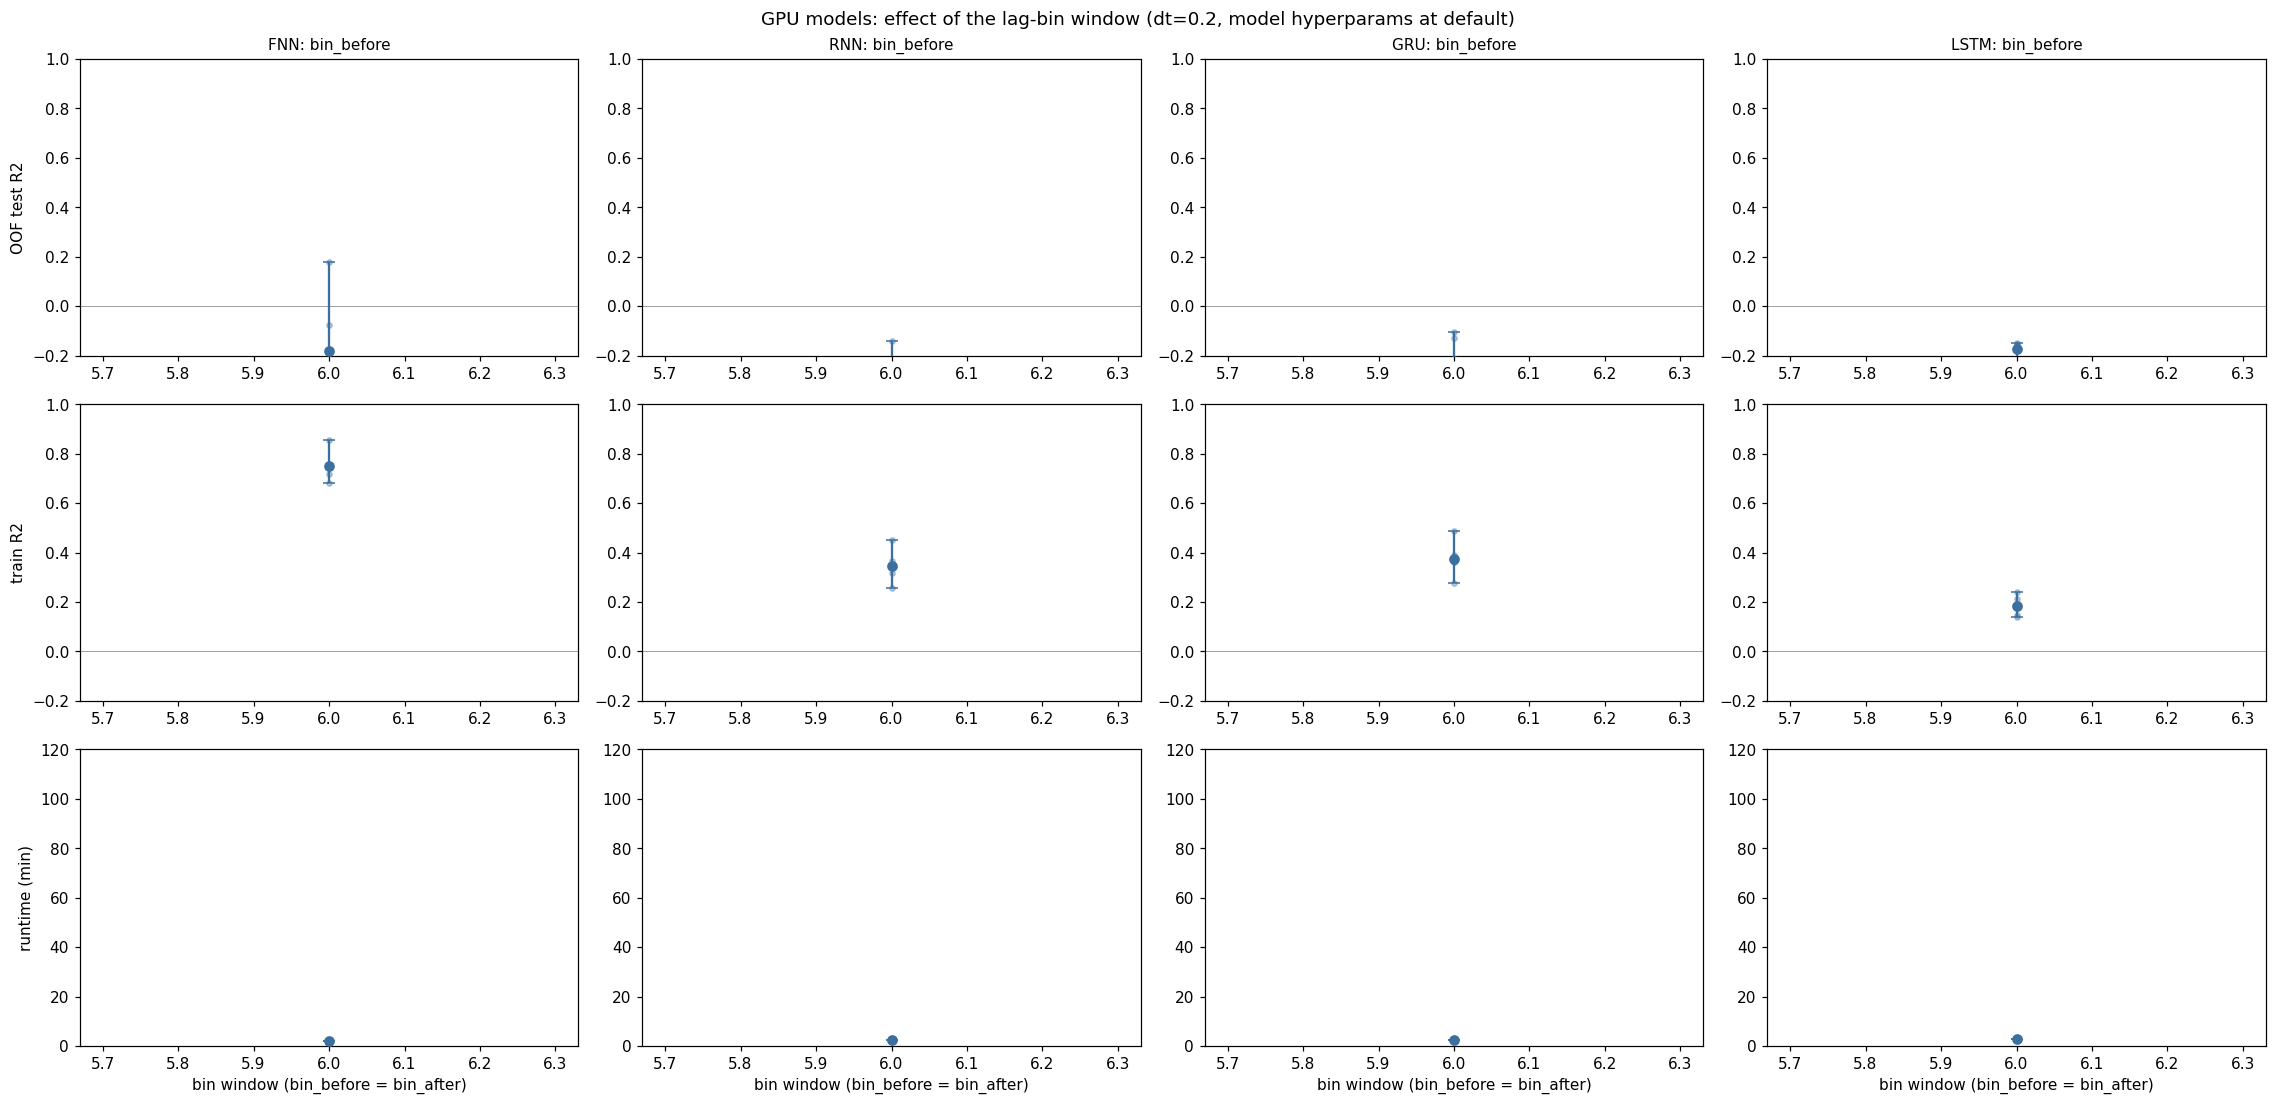

In [14]:
for group_name, models in [("CPU", CPU_MODELS), ("GPU", GPU_MODELS)]:
    specs = []
    for model in models:
        default = MODEL_DEFAULTS.get(model, {})
        fixed = {**default, "dt": PREPROC_DEFAULTS["dt"], "n_splits": PREPROC_DEFAULTS["n_splits"],
                 "spike_thresh": PREPROC_DEFAULTS["spike_thresh"]}
        specs.append({"model": model, "x": "bin_before", "fixed": fixed, "xlabel": "bin window (bin_before = bin_after)"})
    panel_grid(specs, f"{group_name} models: effect of the lag-bin window (dt=0.2, model hyperparams at default)",
              f"bin_window_sweep_{group_name.lower()}.png")

[no data yet] WF: n_splits (oof_r2, fixed={'dt': 0.2, 'bin_before': 6, 'spike_thresh': 0})
[no data yet] WF: n_splits (mean_fold_train_r2, fixed={'dt': 0.2, 'bin_before': 6, 'spike_thresh': 0})
[no data yet] WF: n_splits (runtime_min, fixed={'dt': 0.2, 'bin_before': 6, 'spike_thresh': 0})


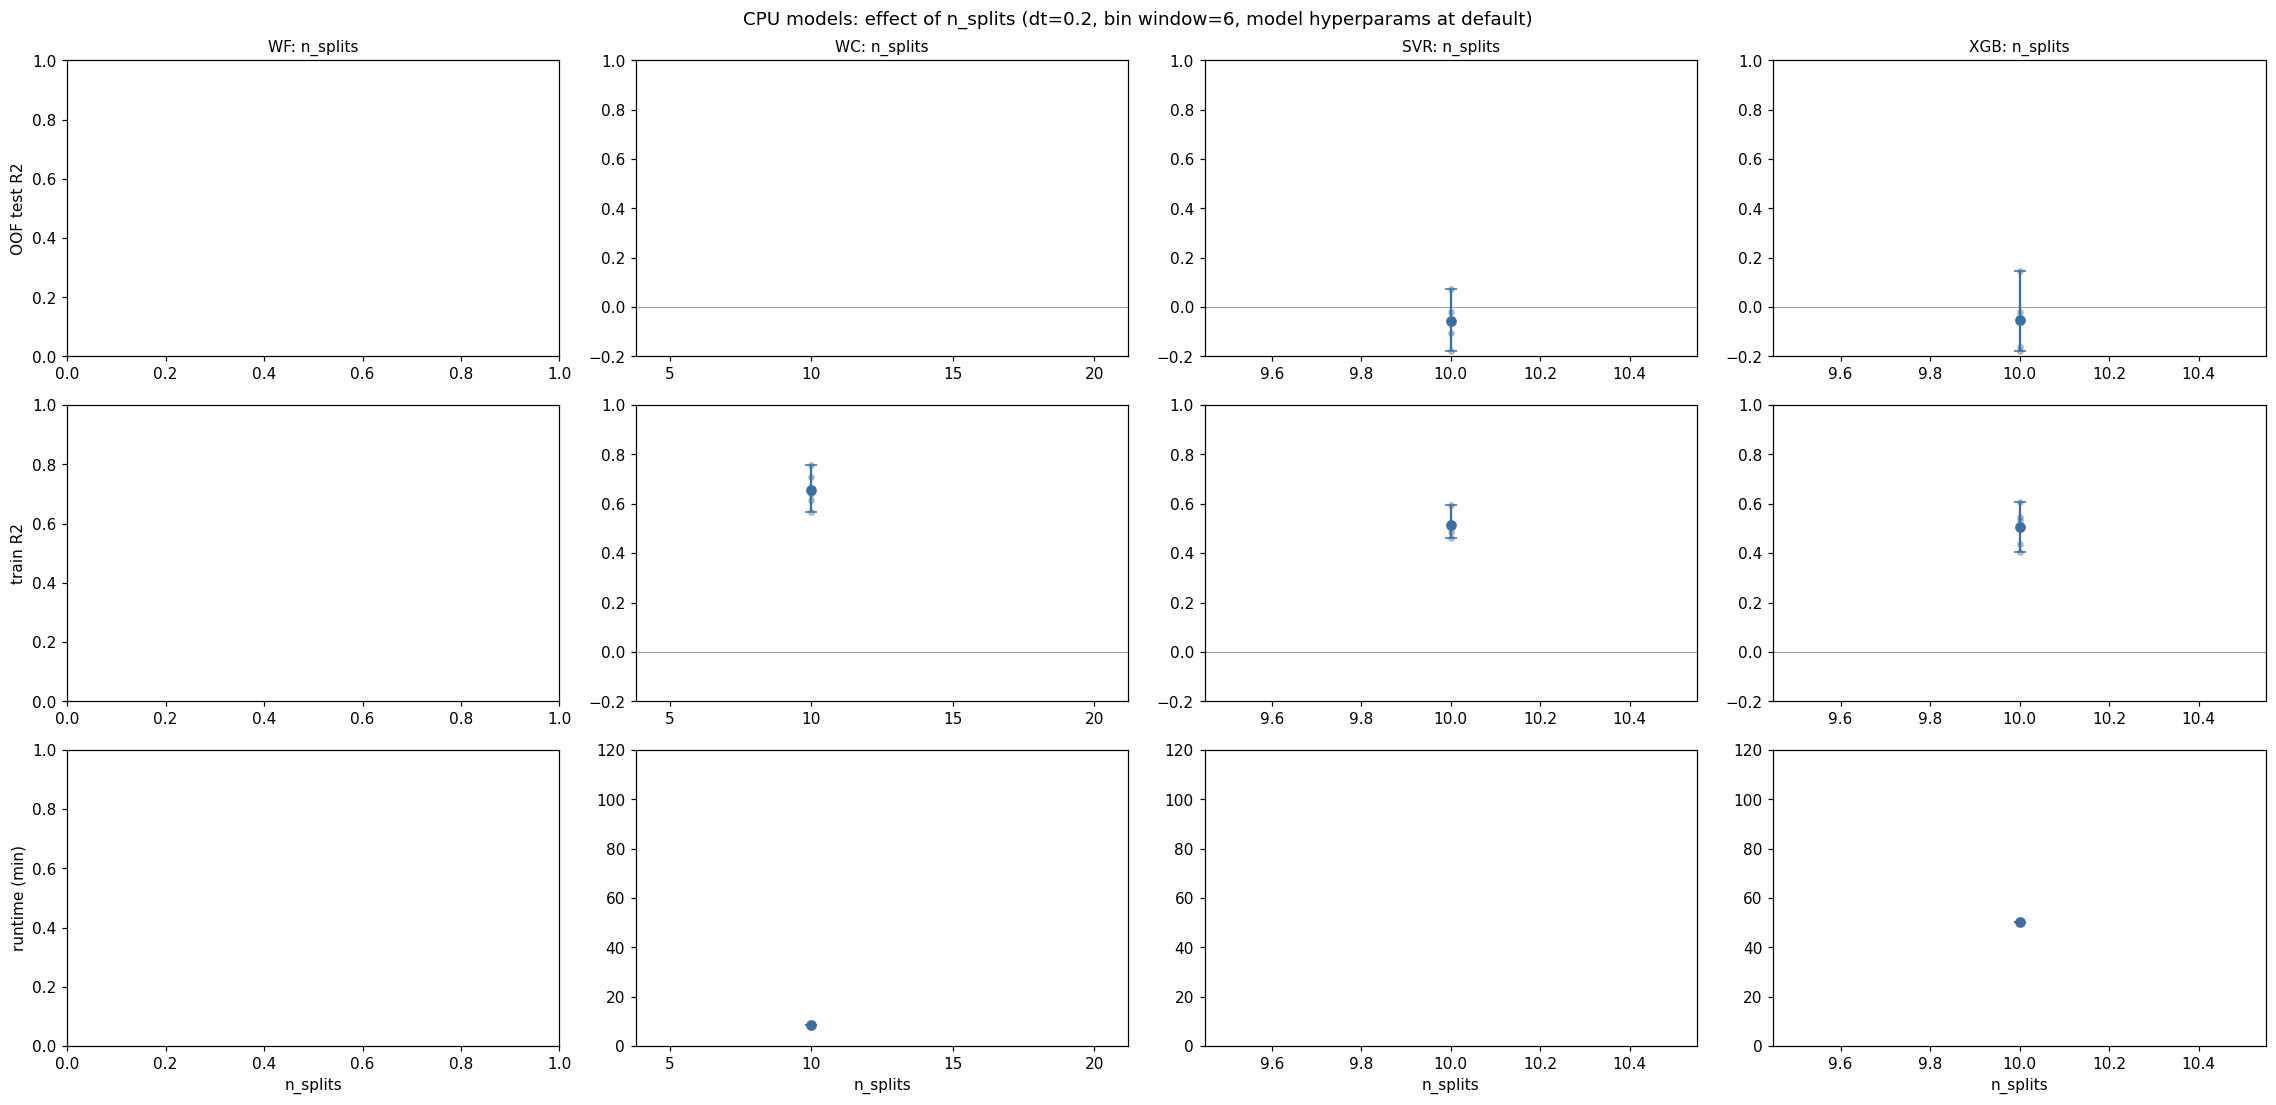

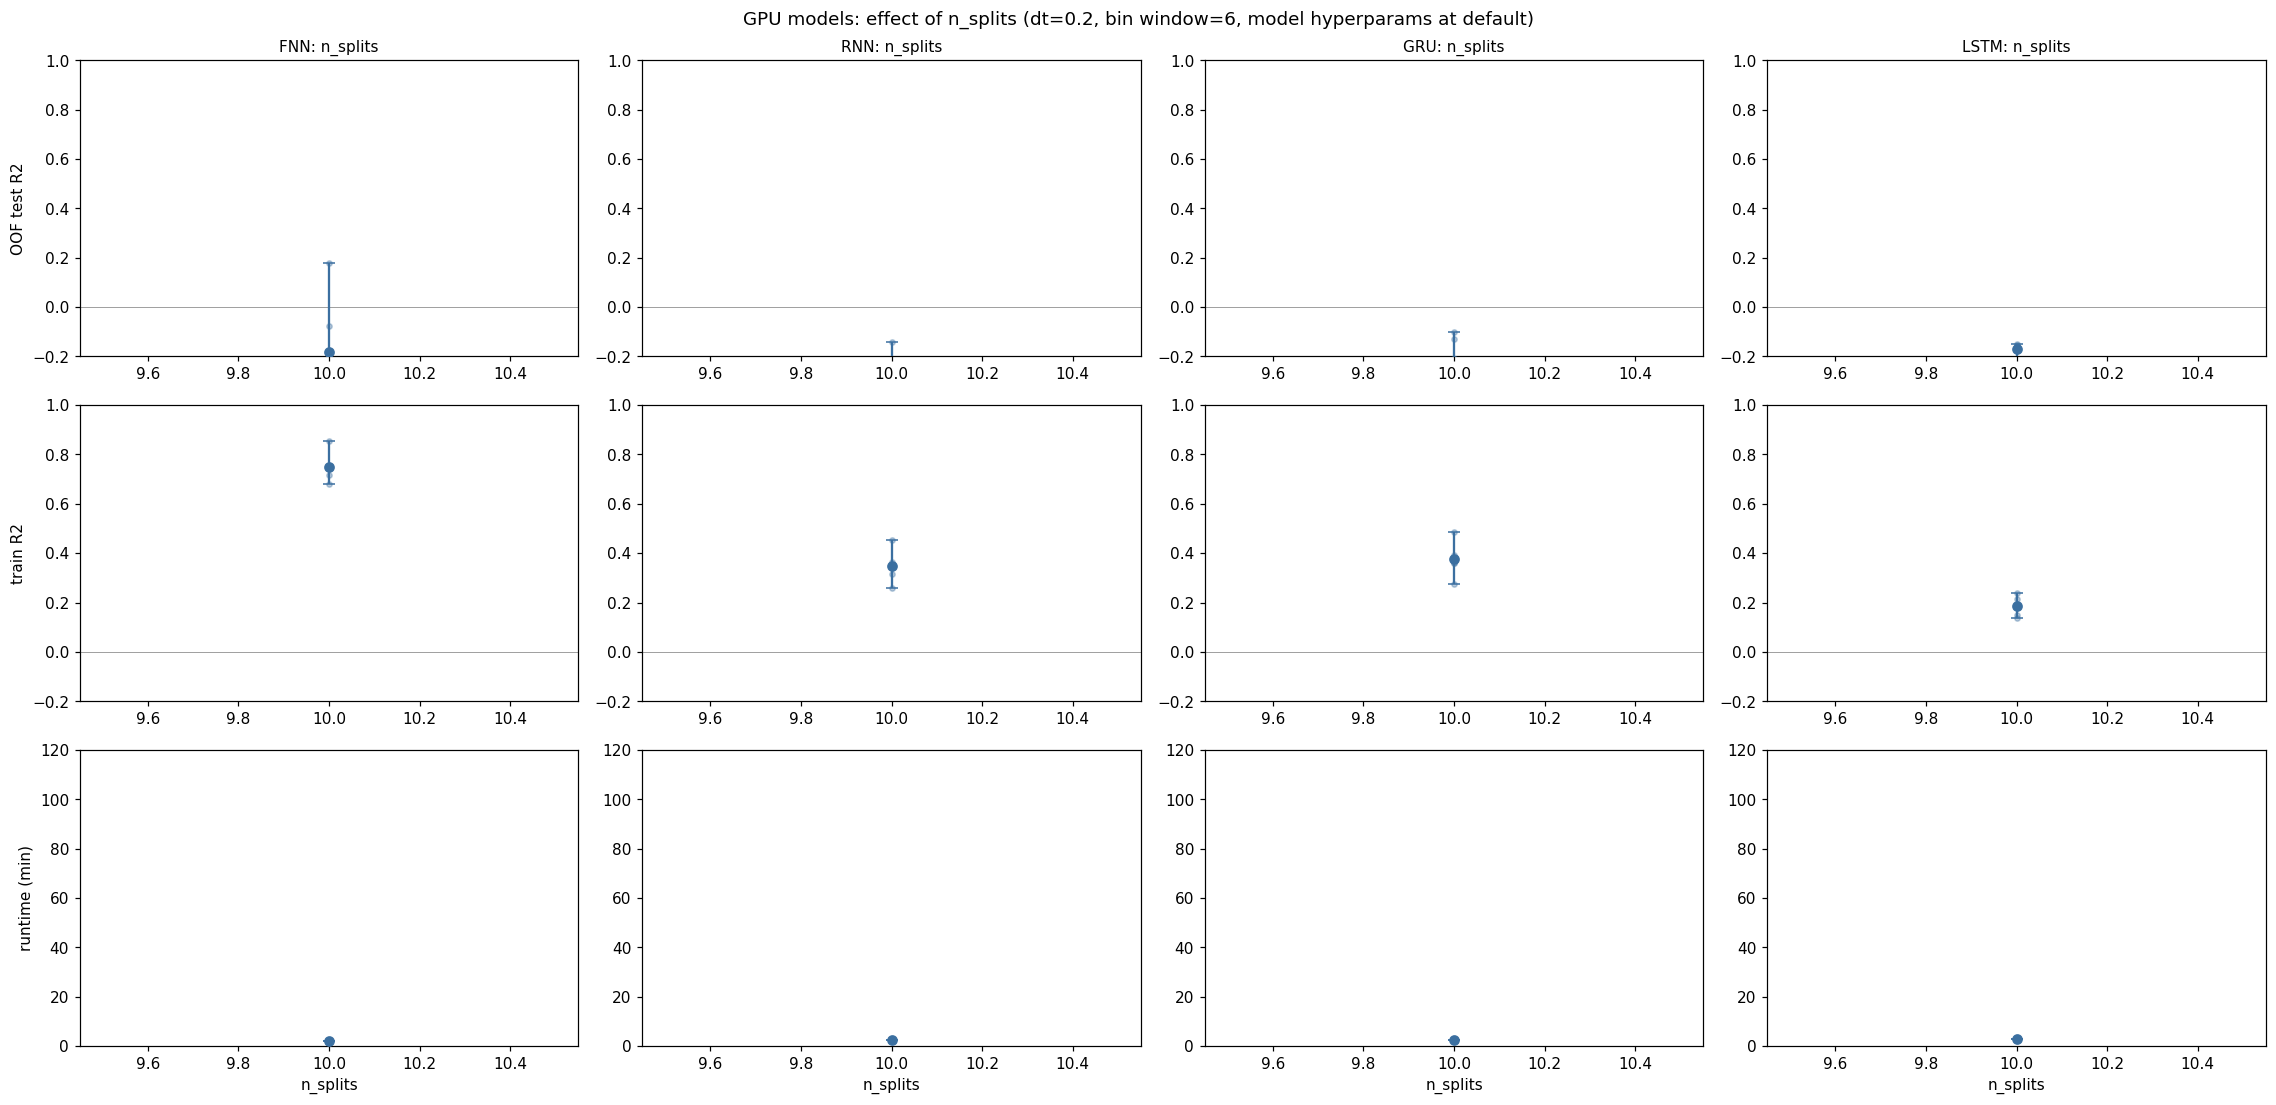

In [15]:
for group_name, models in [("CPU", CPU_MODELS), ("GPU", GPU_MODELS)]:
    specs = []
    for model in models:
        default = MODEL_DEFAULTS.get(model, {})
        fixed = {**default, "dt": PREPROC_DEFAULTS["dt"], "bin_before": PREPROC_DEFAULTS["bin_before"],
                 "spike_thresh": PREPROC_DEFAULTS["spike_thresh"]}
        specs.append({"model": model, "x": "n_splits", "fixed": fixed})
    panel_grid(specs, f"{group_name} models: effect of n_splits (dt=0.2, bin window=6, model hyperparams at default)",
              f"n_splits_sweep_{group_name.lower()}.png")

## Spike-count threshold sweep — `spike_thresh`

Drops channels with fewer than this many spikes (post drift-correction),
cutting input feature count directly -- see `channel_selection.ipynb` for
where the tested values came from. Applied at each model's default
hyperparams and default dt/bin/n_splits.

[no data yet] WF: spike_thresh (oof_r2, fixed={'dt': 0.2, 'bin_before': 6, 'n_splits': 10})
<cell 5>:55: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
<cell 5>:55: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
<cell 5>:55: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
[no data yet] WF: spike_thresh (mean_fold_train_r2, fixed={'dt': 0.2, 'bin_before': 6, 'n_splits': 10})
<cell 5>:55: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
<cell 5>:55: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
<cell 5>:55: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
[no data yet] WF: spike_thresh (runtime_min, fixed={'dt': 0.2, 'bin_before': 6, 'n_splits': 10})
<cell 5>:55: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
<cell 5>:55: UserWarning: Data has no positive values, and therefore c

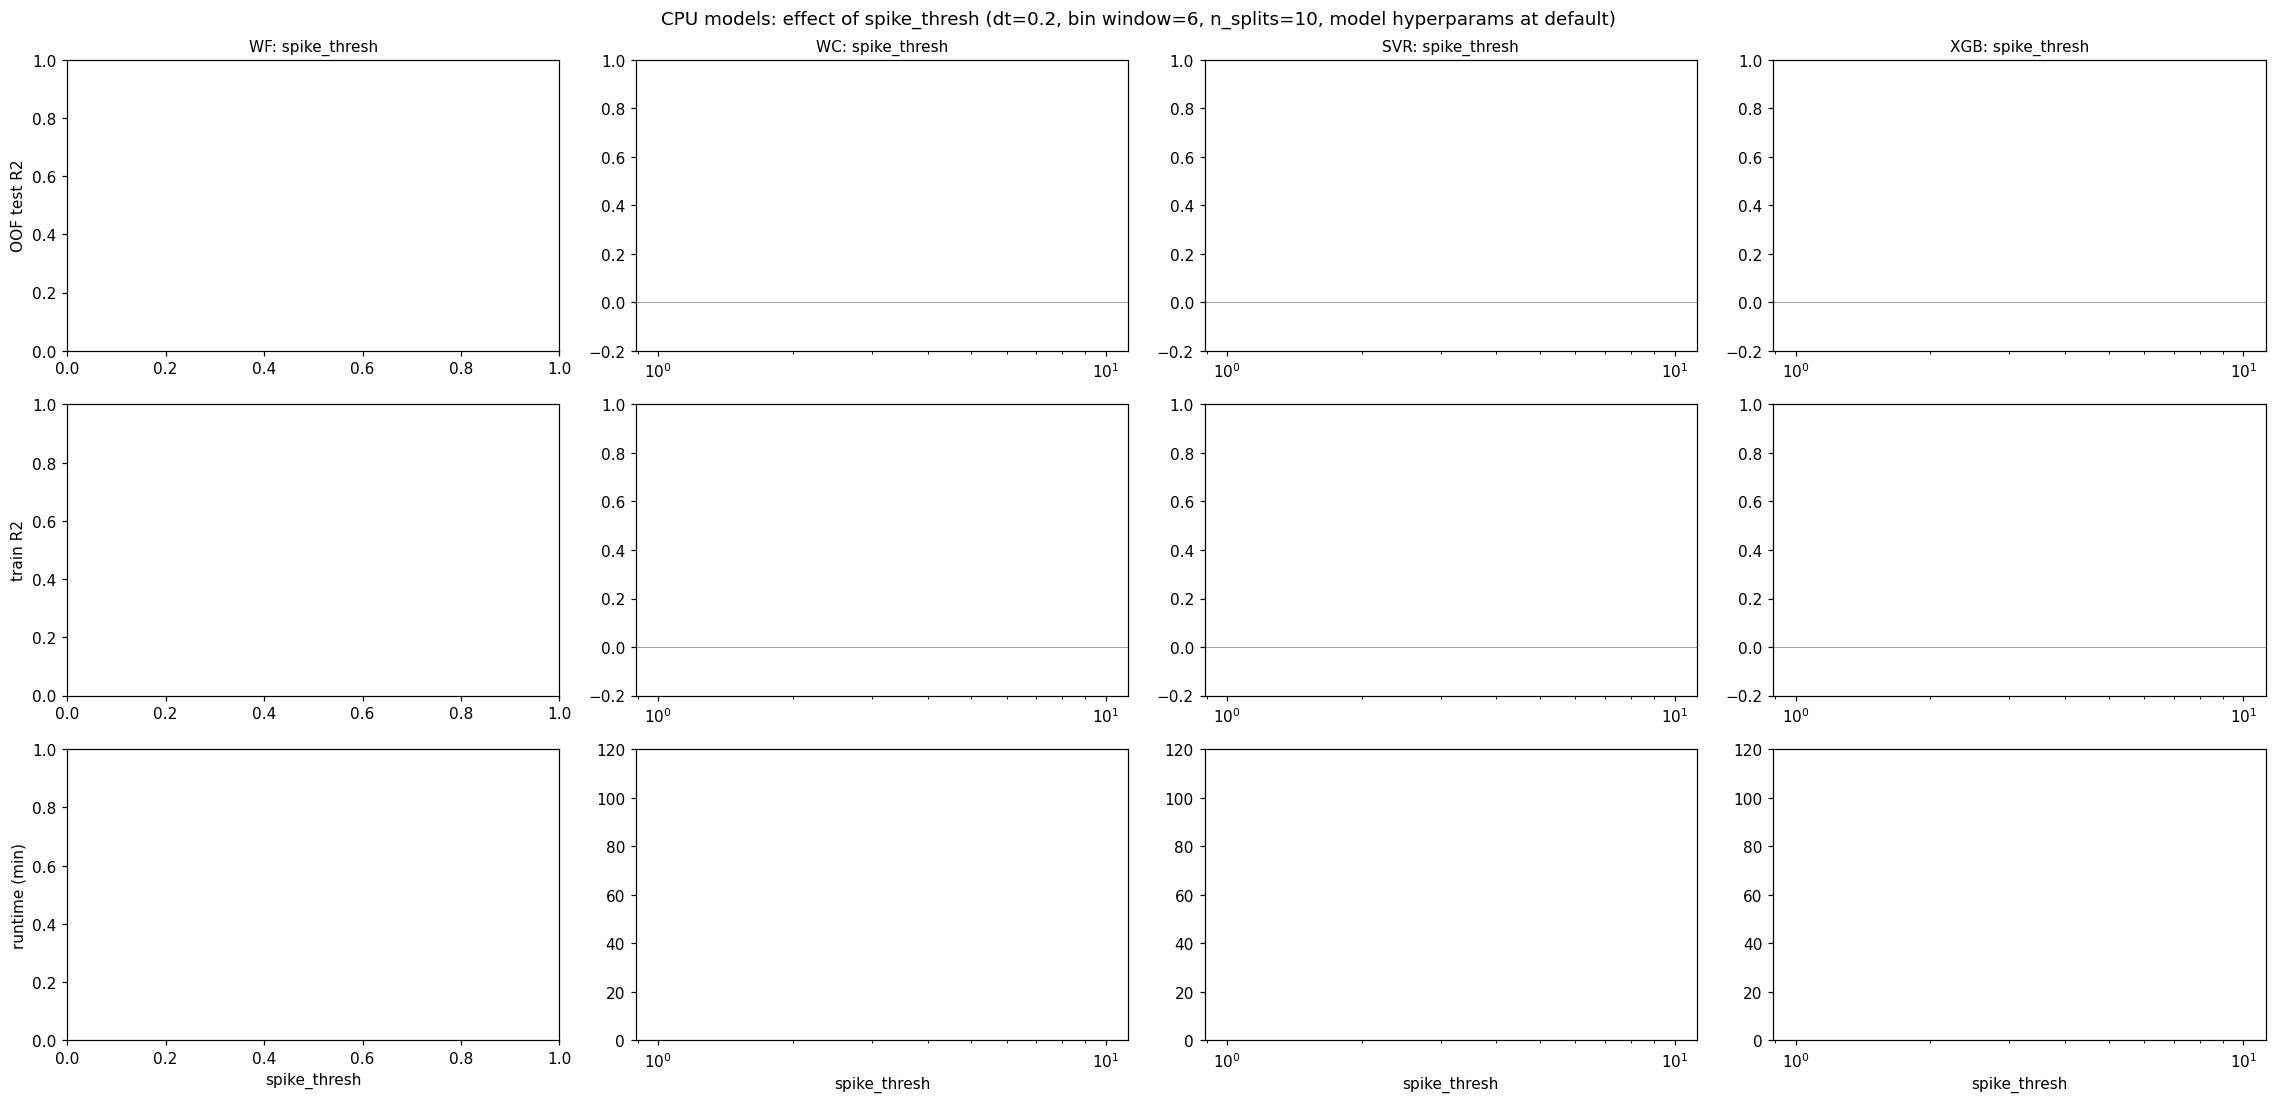

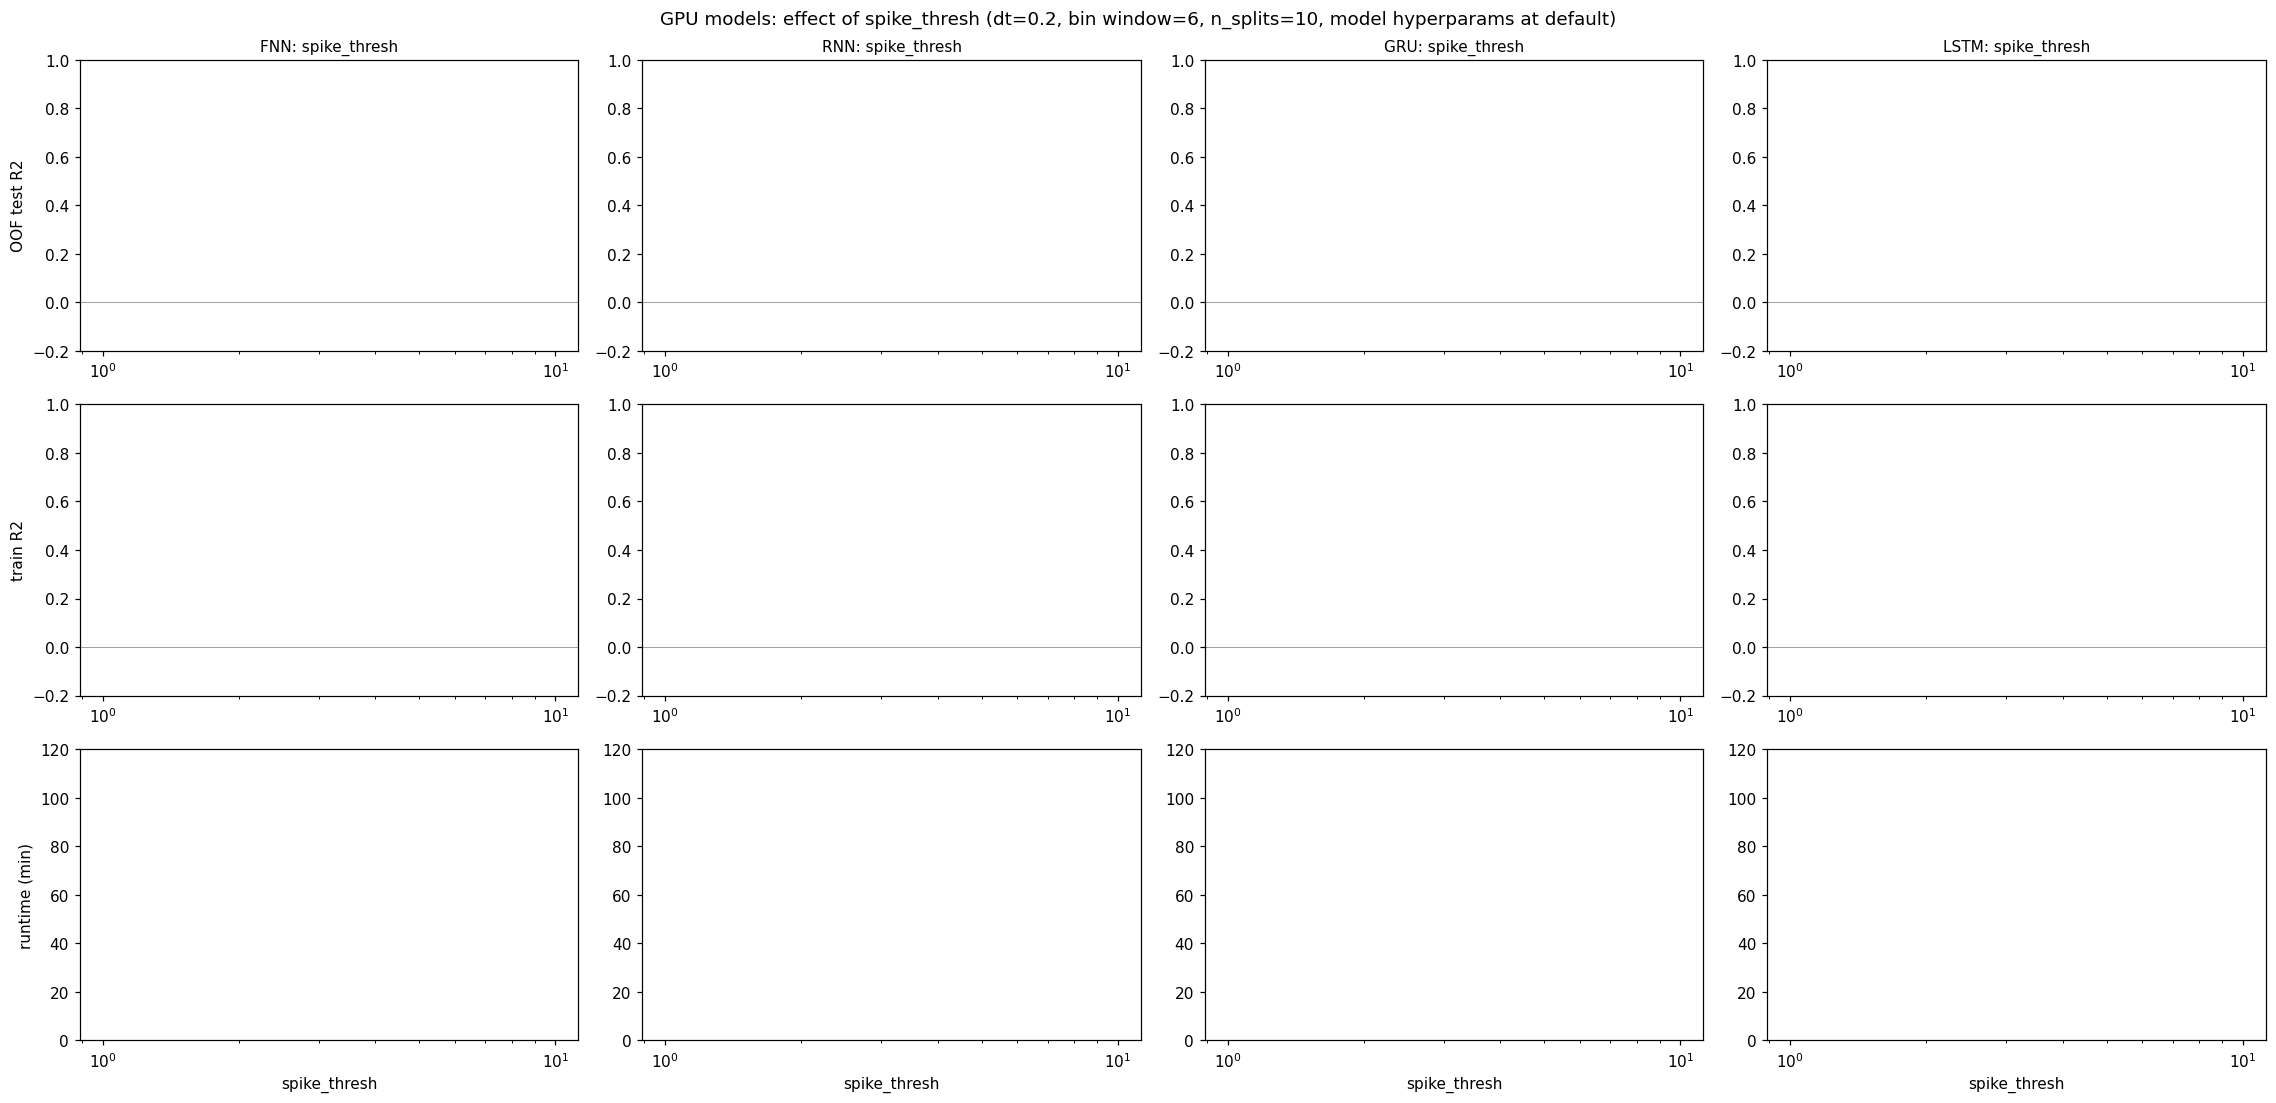

In [16]:
for group_name, models in [("CPU", CPU_MODELS), ("GPU", GPU_MODELS)]:
    specs = []
    for model in models:
        default = MODEL_DEFAULTS.get(model, {})
        fixed = {**default, "dt": PREPROC_DEFAULTS["dt"], "bin_before": PREPROC_DEFAULTS["bin_before"],
                 "n_splits": PREPROC_DEFAULTS["n_splits"]}
        specs.append({"model": model, "x": "spike_thresh", "fixed": fixed})
    panel_grid(specs, f"{group_name} models: effect of spike_thresh (dt=0.2, bin window=6, n_splits=10, model hyperparams at default)",
              f"spike_thresh_sweep_{group_name.lower()}.png", logx=True)

## Everything at once — parallel coordinates, per model

The marginals and heatmaps above each show a slice through a model's
results. This shows **every completed run** for a model on one plot: one
axis per hyperparameter *and* every preprocessing knob that was swept
(`dt`, bin window, `n_splits`, `spike_thresh`), one line per run, colored by
that run's OOF test R² (fixed to the same -0.2..1 scale used everywhere
else, green=better). Runs are drawn best-on-top (sorted so high-R2 lines
aren't buried under the rest) and line opacity backs off automatically as
run count grows, so a model with hundreds of runs doesn't turn into a solid
smear.

Each axis is independently min-max scaled to fill the plot height -- the
numbers at the top/bottom of each axis are that axis's actual min/max, not a
shared scale across axes.

[no data yet] WF


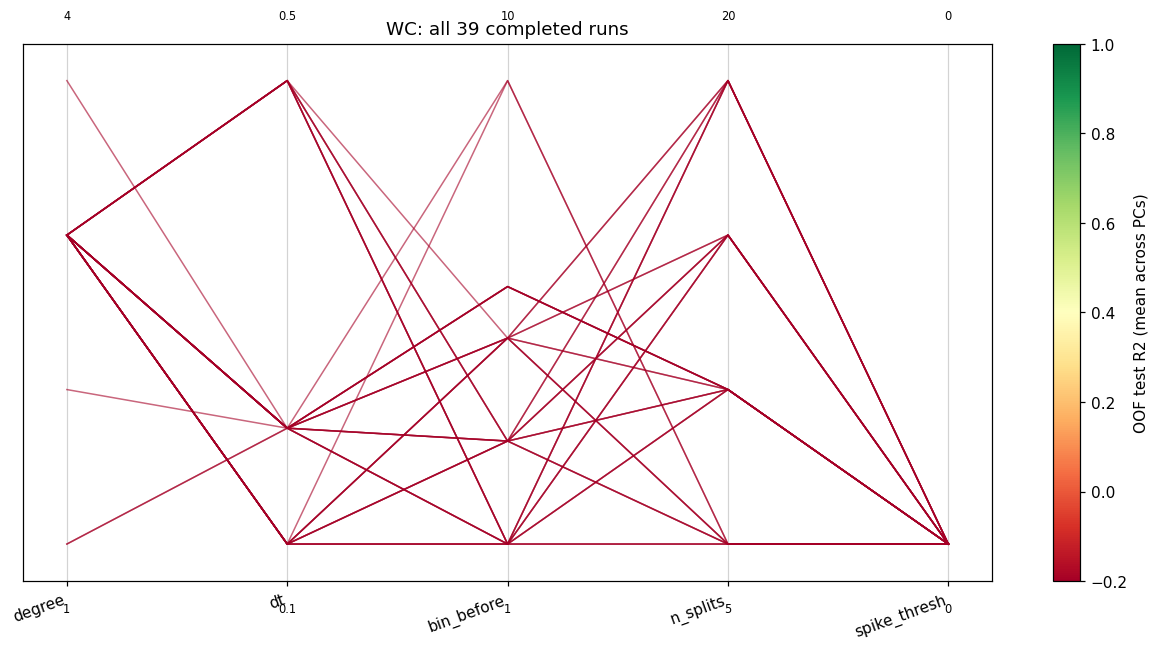

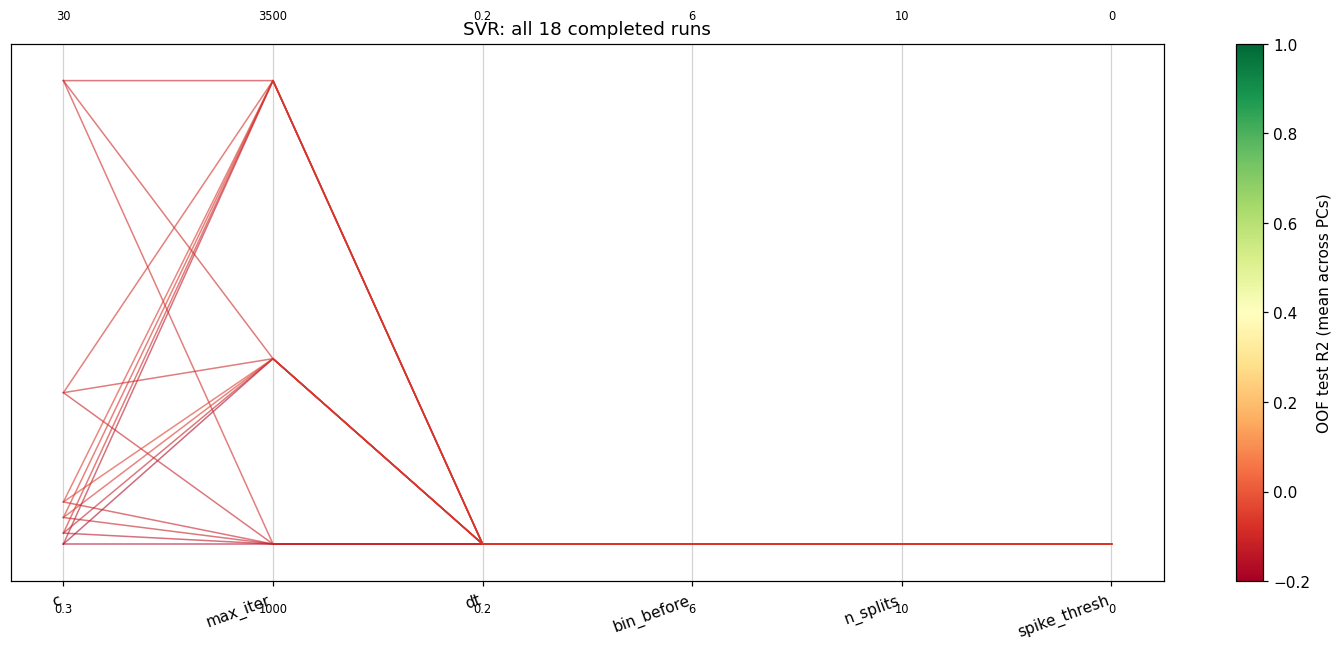

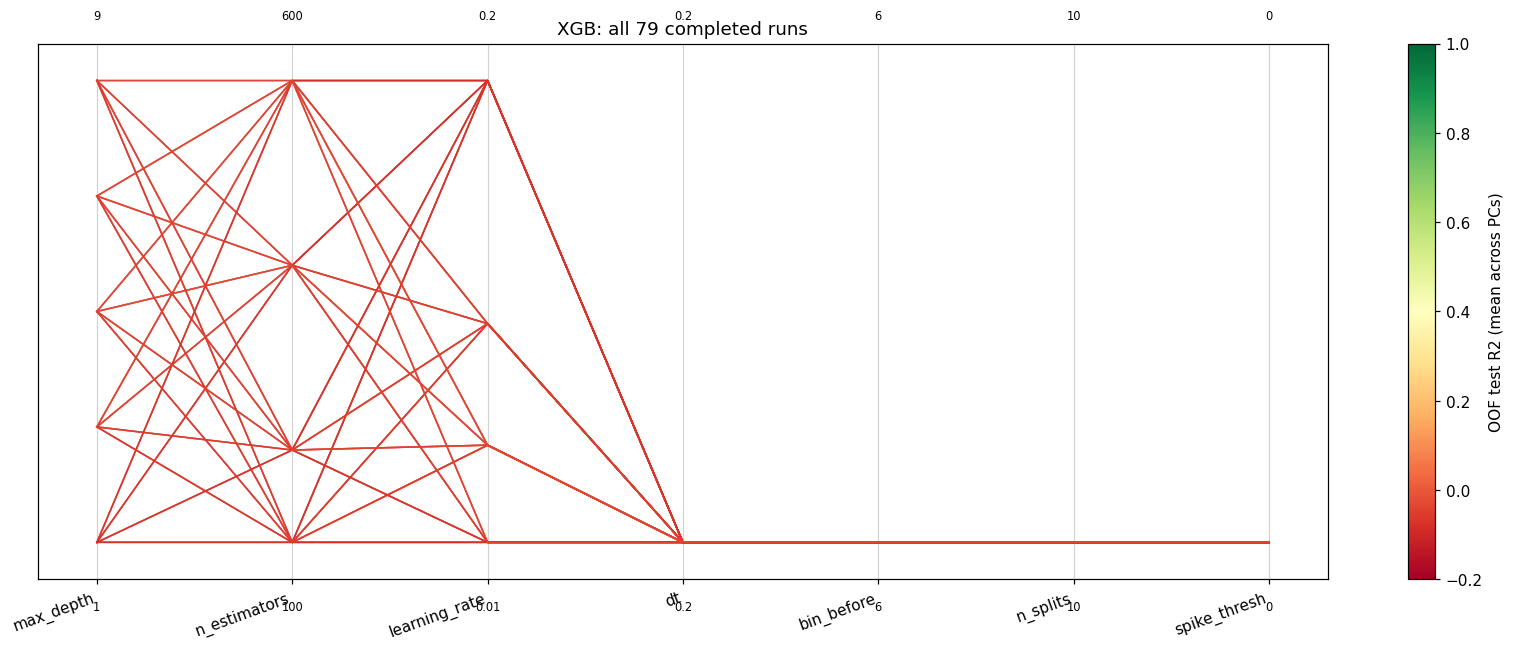

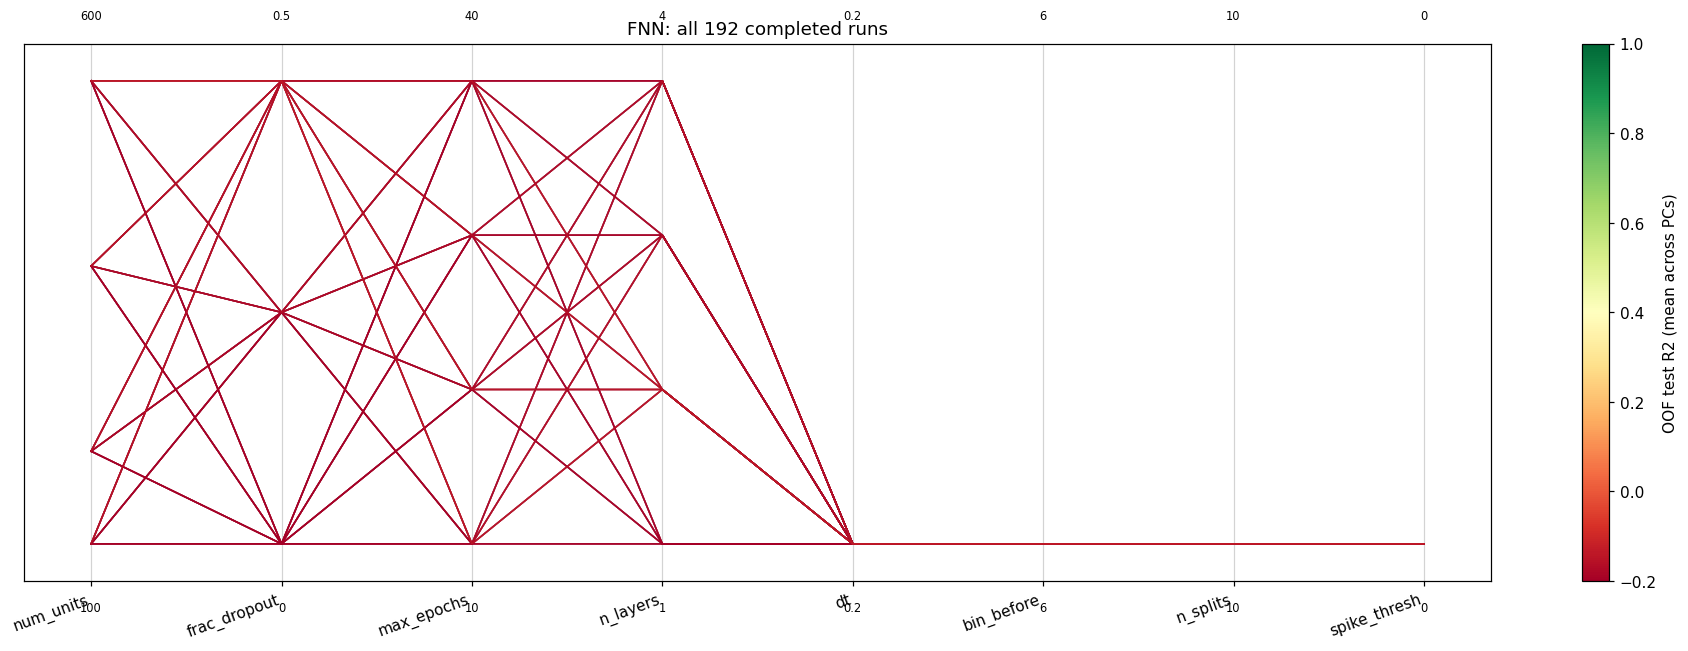

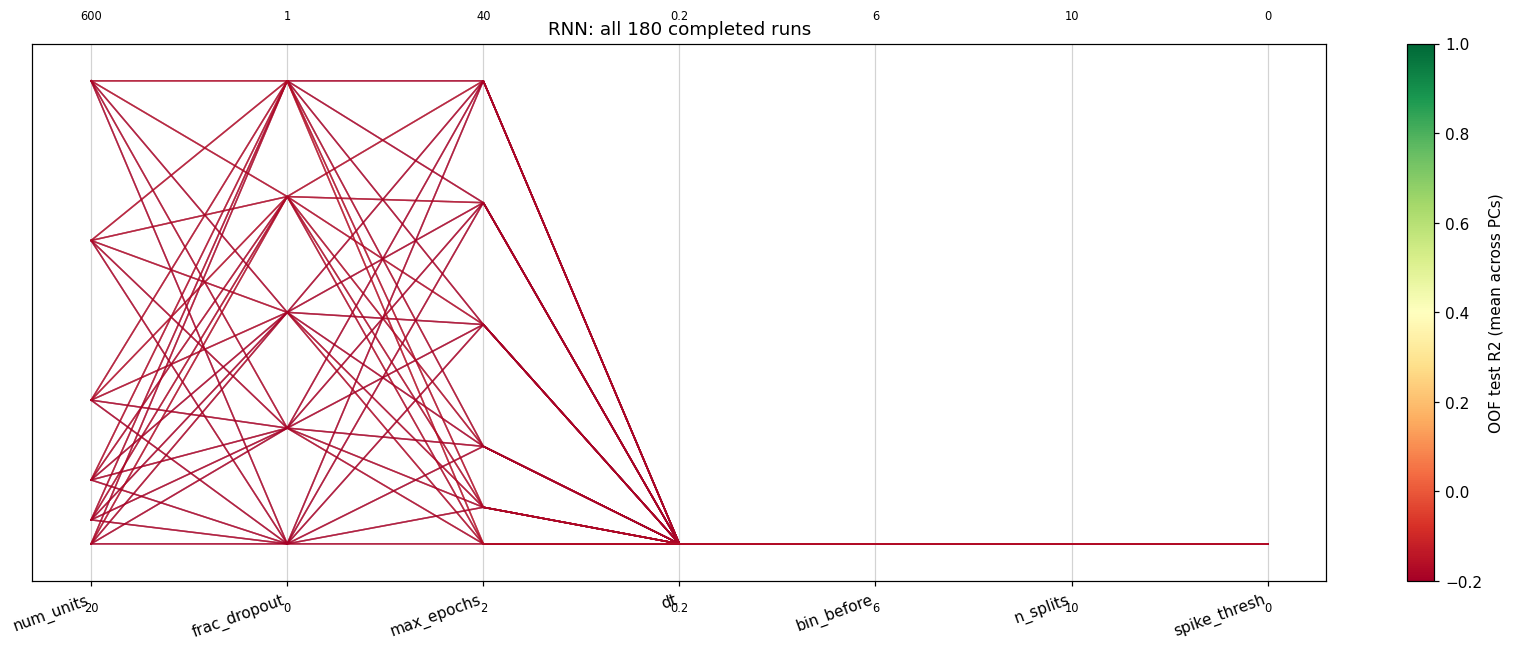

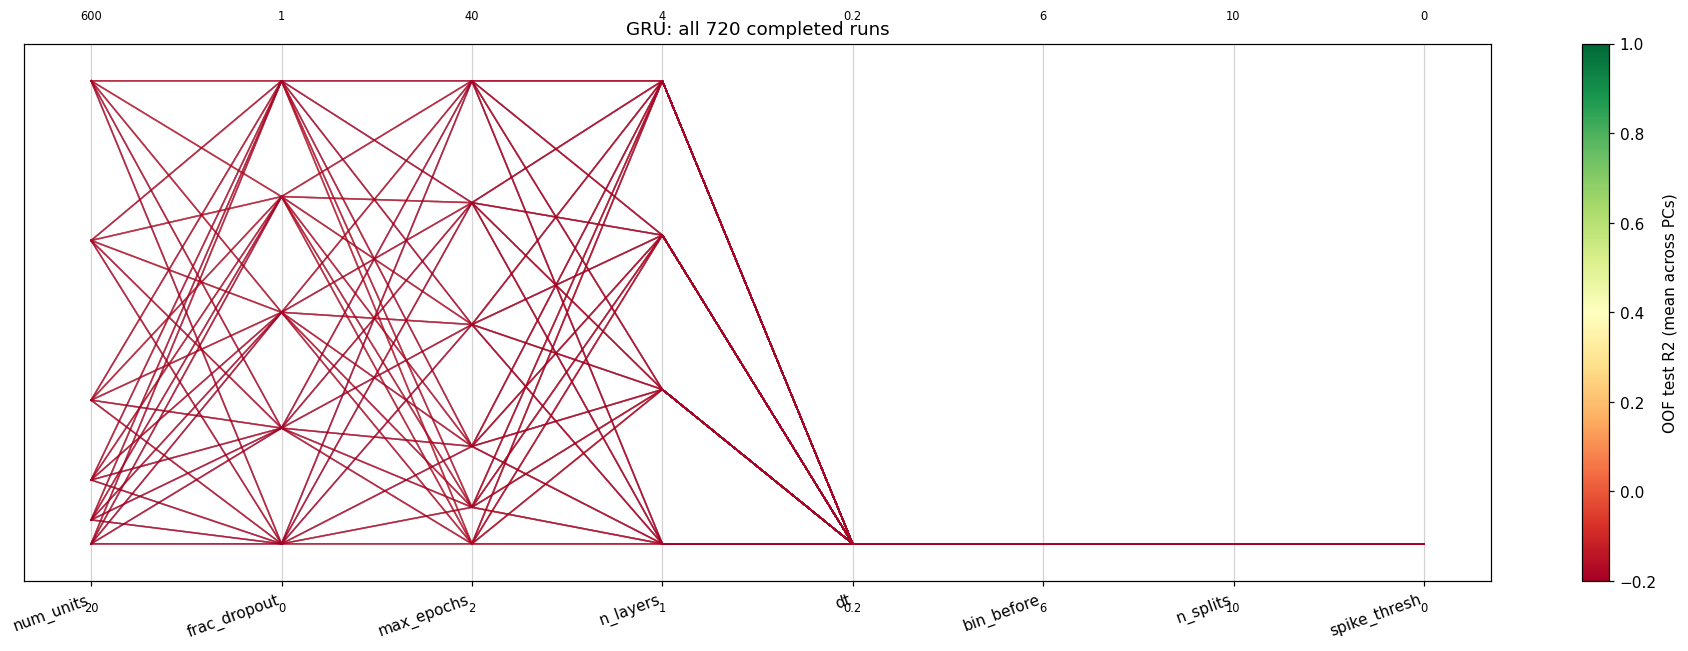

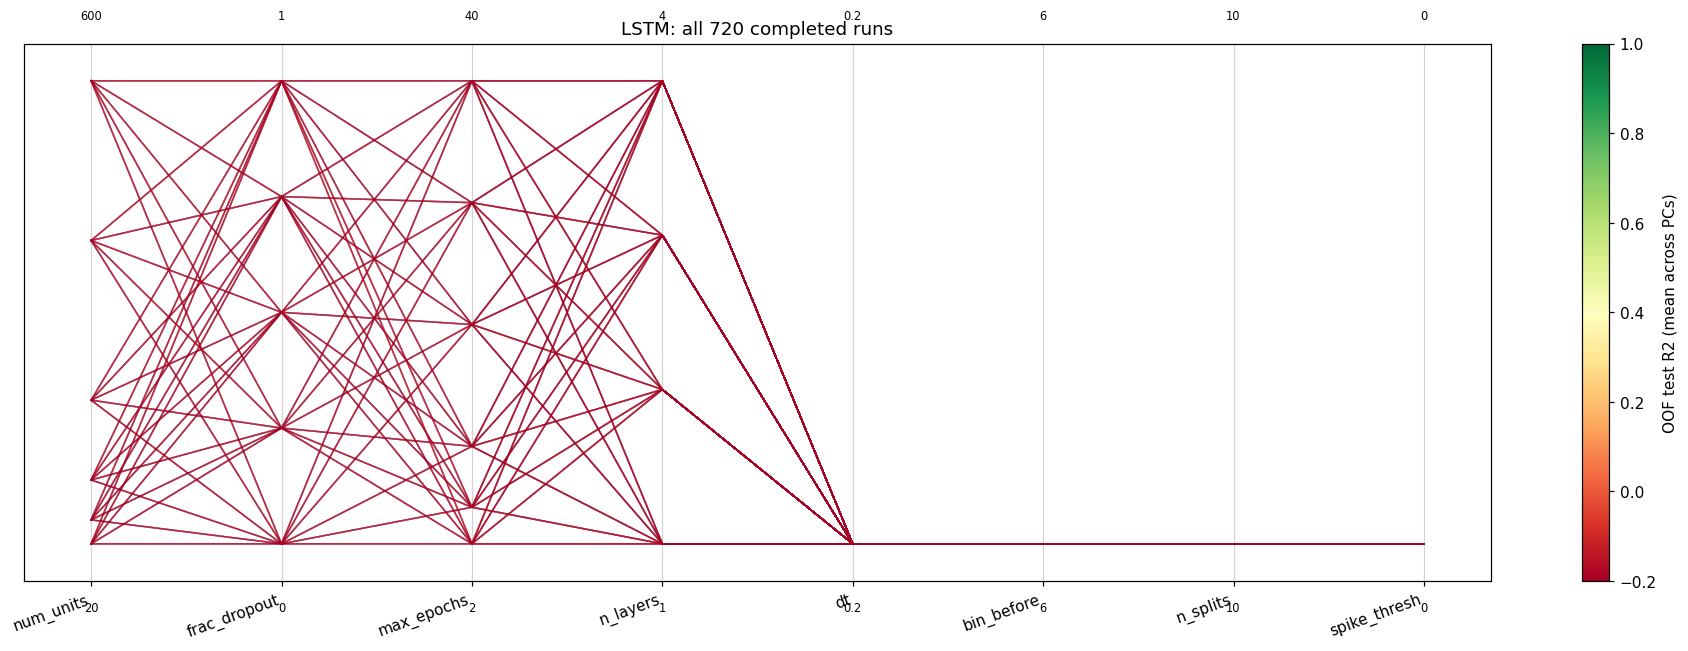

In [17]:
def parallel_coordinates_plot(df, model, savepath):
    hp_cols = MODEL_HP_COLS.get(model, [])
    axes_cols = hp_cols + ["dt", "bin_before", "n_splits", "spike_thresh"]
    sub = df[df.model == model].dropna(subset=["oof_r2"])
    if sub.empty:
        print(f"[no data yet] {model}")
        return None

    agg = sub.groupby("run_dir").agg({**{c: "first" for c in axes_cols}, "oof_r2": "mean"}).reset_index()
    agg = agg.sort_values("oof_r2")  # best drawn last (on top)

    mins, maxs = agg[axes_cols].min(), agg[axes_cols].max()
    ranges = (maxs - mins).replace(0, 1)  # constant column -> avoid div-by-zero, draws flat

    norm = plt.Normalize(*R2_YLIM)
    cmap = plt.cm.RdYlGn
    alpha = float(np.clip(50 / len(agg), 0.05, 0.6))

    n_axes = len(axes_cols)
    fig, ax = plt.subplots(figsize=(1.9 * n_axes + 2, 6))
    x = np.arange(n_axes)
    for _, row in agg.iterrows():
        y = [(row[c] - mins[c]) / ranges[c] for c in axes_cols]
        ax.plot(x, y, color=cmap(norm(np.clip(row["oof_r2"], *R2_YLIM))), alpha=alpha, linewidth=1)

    prefix = f"{model.lower()}_"
    ax.set_xticks(x)
    ax.set_xticklabels([c[len(prefix):] if c.startswith(prefix) else c for c in axes_cols], rotation=20, ha="right")
    ax.set_yticks([])
    for i, c in enumerate(axes_cols):
        ax.axvline(i, color="lightgray", linewidth=0.8, zorder=0)
        ax.text(i, -0.04, f"{mins[c]:g}", ha="center", va="top", fontsize=7.5, transform=ax.get_xaxis_transform())
        ax.text(i, 1.04, f"{maxs[c]:g}", ha="center", va="bottom", fontsize=7.5, transform=ax.get_xaxis_transform())
    ax.set_ylim(-0.08, 1.08)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    fig.colorbar(sm, ax=ax, label="OOF test R2 (mean across PCs)")
    ax.set_title(f"{model}: all {len(agg)} completed runs")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / savepath, dpi=150)
    plt.show()
    return fig

for model in CPU_MODELS + GPU_MODELS:
    parallel_coordinates_plot(df, model, f"parallel_coords_{model}.png")

## Leaderboard — best configuration found so far, per model family

Best run selected by mean OOF test R² across PCs; its train R² and runtime
are shown for that same run (not re-optimized separately). Same 3-row layout,
one column: all models side by side within each row.

model                             best_run                                                                                   best_hyperparams     test_mean      test_min     test_max  train_mean  train_min  train_max  runtime_min  n_runs_tested
  XGB   20260808_064208_XGB_d5_n600_lr0.05                       {'xgb_max_depth': 5.0, 'xgb_n_estimators': 600.0, 'xgb_learning_rate': 0.05}     -0.031264     -0.207551     0.252533    0.872697   0.836883   0.916027   174.300000             79
  SVR      20260808_023103_SVR_c3.0_mi2000                                                             {'svr_c': 3.0, 'svr_max_iter': 2000.0}     -0.057759     -0.177374     0.074469    0.514910   0.461443   0.593575   250.066667             18
  FNN 20260808_104428_FNN_u600_do0.5_e20_1     {'fnn_num_units': 600.0, 'fnn_frac_dropout': 0.5, 'fnn_max_epochs': 20.0, 'fnn_n_layers': 4.0}     -0.123312     -0.345667     0.150726    0.663721   0.604000   0.753315     3.383333            192
  GRU   20260808_130

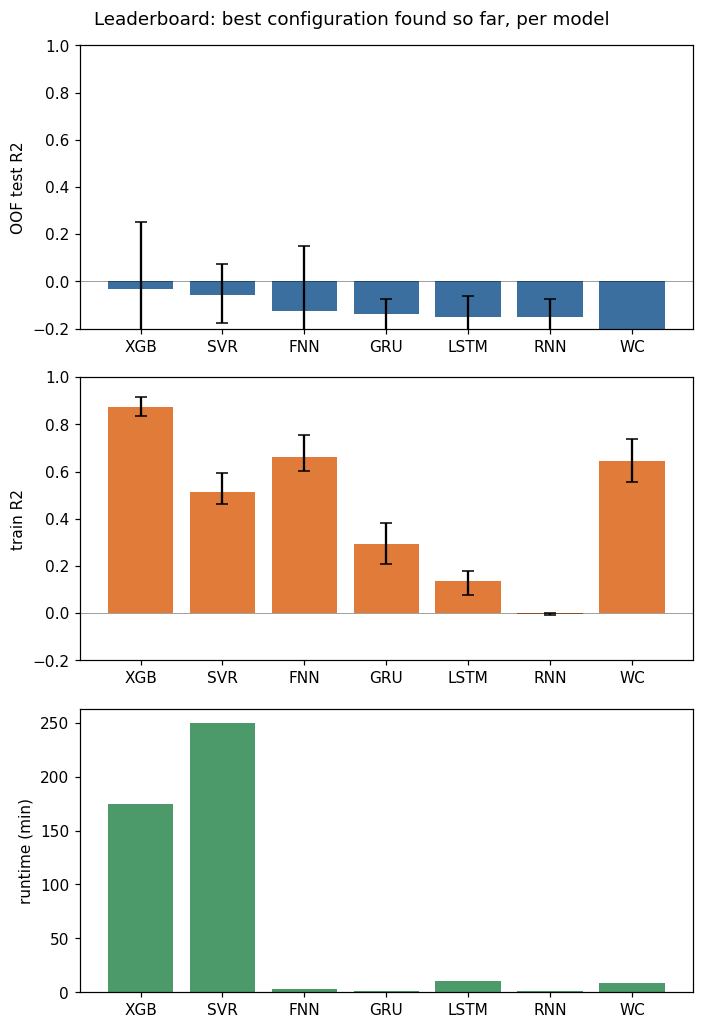

In [18]:
def leaderboard(df, metric="oof_r2"):
    recs = []
    for model, sub in df.groupby("model"):
        by_run = sub.groupby("run_dir")[metric].mean()
        if by_run.empty:
            continue
        best_run = by_run.idxmax()
        best = sub[sub.run_dir == best_run]
        hp_cols = MODEL_HP_COLS.get(model, [])
        best_hp = {c: best[c].iloc[0] for c in hp_cols}
        recs.append({
            "model": model, "best_run": best_run, "best_hyperparams": best_hp,
            "test_mean": best["oof_r2"].mean(), "test_min": best["oof_r2"].min(), "test_max": best["oof_r2"].max(),
            "train_mean": best["mean_fold_train_r2"].mean(),
            "train_min": best["mean_fold_train_r2"].min(), "train_max": best["mean_fold_train_r2"].max(),
            "runtime_min": best["runtime_min"].iloc[0],
            "n_runs_tested": sub.run_dir.nunique(),
        })
    return pd.DataFrame(recs).sort_values("test_mean", ascending=False)

lb = leaderboard(df)
lb.to_csv(PLOTS_DIR / "leaderboard.csv", index=False)
print(lb.to_string(index=False))

fig, axes = plt.subplots(3, 1, figsize=(6.5, 9.5))
x = np.arange(len(lb))
test_err = np.vstack([(lb.test_mean - lb.test_min).clip(lower=0), (lb.test_max - lb.test_mean).clip(lower=0)])
train_err = np.vstack([(lb.train_mean - lb.train_min).clip(lower=0), (lb.train_max - lb.train_mean).clip(lower=0)])
axes[0].bar(x, lb.test_mean, yerr=test_err, capsize=4, color="#3B6FA0")
axes[0].axhline(0, color="black", linewidth=0.6, alpha=0.4)
axes[0].set_ylim(*R2_YLIM); axes[0].set_ylabel("OOF test R2")
axes[1].bar(x, lb.train_mean, yerr=train_err, capsize=4, color="#E07B39")
axes[1].axhline(0, color="black", linewidth=0.6, alpha=0.4)
axes[1].set_ylim(*R2_YLIM); axes[1].set_ylabel("train R2")
axes[2].bar(x, lb.runtime_min, color="#4C9A6A")
axes[2].set_ylabel("runtime (min)")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(lb.model)
fig.suptitle("Leaderboard: best configuration found so far, per model")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "leaderboard.png", dpi=150)
plt.show()

## Next steps

- No config has been scored on the true holdout yet. Once a winner looks
  stable across re-runs of this notebook, re-launch it once with
  `--evaluate-holdout` before reporting a final number.
- See the coverage cell above for what's been tested per model; `python
  build_search_grid.py` (in `scripts/theo_decoding/`) reports exactly which
  grid points are still missing/queued against the live `results/` folder.